# Notebook 2 — Análise Estatística e Modelagem

# Capstone Project | Liga <a class="anchor" id="Cpstone"></a>

**Authors:**\
Maria Margarida Mouteira Guerreiro Romero Antelo <a20243063@pbs.up.pt>\
Mariana Chaves Santos <a20243060@pbs.up.pt>\
Mónica Isabel da Silva Simões <a20250187@pbs.up.pt>\
Hugo Miguel Carvalho da Silva Glória <a20250093@pbs.up.pt>\
Rui Alexandre Paiva Santos <a20160686@pbs.up.pt>
>
> Publication Date: October 2025

**Table of contents:**
1. [Install required packages](#required_packages)
2. [Define program variables and setup db connection](#operators)
3. [Declare database manager helping functions](#db_manager)
4. [Declare technician assignment function](#logical_operators)
5. [Declare random intervencion close](#comparison_operators)
6. [Main program](#main)

---

Rat, Shr e Rch — são métricas fundamentais no mundo da medição de audiência televisiva. Eles ajudam a entender como um programa, canal ou campanha publicitária está performando, mas cada um foca em um aspecto diferente.

RAT (Rating)
O Rating (também conhecido como Rat%) é a métrica mais tradicional e mede a porcentagem do universo total de TVs ligadas e desligadas que está sintonizada em um determinado programa ou canal.

O que ele mostra: A popularidade absoluta de um programa. Se um programa tem um Rating de 5%, significa que 5% de todas as TVs na área de pesquisa (incluindo as desligadas) estão assistindo a esse programa.

Como é calculado: Número de pessoas ou domicílios assistindo a um programa / Universo total de pessoas ou domicílios.

Para que serve: É usado para comparar o desempenho de programas em diferentes horários e para negociar o valor de espaços publicitários, já que indica o tamanho da audiência potencial.

SHR (Share)
O Share (ou Shr%) mede a porcentagem de audiência de um programa ou canal em relação apenas às TVs que estão ligadas no momento.

O que ele mostra: A "fatia de mercado" que um programa ou canal tem. Se um programa tem um Share de 20%, significa que 20% das pessoas que estão assistindo TV naquele momento estão sintonizadas nele.

Como é calculado: Audiência do programa / Total de TVs ligadas.

Para que serve: É útil para entender o desempenho de um programa em relação à concorrência direta no mesmo horário. Um Share alto indica que o programa é líder de audiência, mesmo que o número total de pessoas assistindo TV naquele momento seja menor.

RCH (Reach)
O Reach (ou Rch%) mede o alcance de uma campanha publicitária ou programa, mostrando a porcentagem de indivíduos que foram expostos ao conteúdo por pelo menos um minuto, sem contar a duplicação.

O que ele mostra: O tamanho da audiência única que foi alcançada. Se uma campanha publicitária teve um Reach de 40%, significa que 40% das pessoas no universo pesquisado viram pelo menos um dos anúncios.

Como é calculado: Número de pessoas únicas que assistiram ao conteúdo / Universo total de pessoas.

Para que serve: É crucial para planejar campanhas publicitárias, pois indica a capacidade de um programa ou canal de atingir um grande número de pessoas diferentes.

Exemplo Prático
Imagine uma cidade com 1.000 TVs. Em um determinado momento:

500 TVs estão ligadas.

200 TVs estão sintonizadas no Canal A.

Nesse caso:

RAT: O Canal A tem um Rating de 20% (200 TVs / 1.000 TVs). Isso mostra que 20% de todas as TVs da cidade estão assistindo a ele.

SHR: O Canal A tem um Share de 40% (200 TVs / 500 TVs). Isso mostra que ele tem 40% da audiência entre as pessoas que estão com a TV ligada.

Agora, se a campanha publicitária do Canal A teve um RCH de 50%, significa que, ao longo de sua duração, ela alcançou 500 pessoas únicas (50% de 1.000), mesmo que algumas delas tenham assistido a mais de um anúncio.

## Setup working directories <a class="anchor" id="folder_structure"></a>
---

In [1]:
import sys 
import os 
from dotenv import load_dotenv

# Determinar o diretório raiz do projeto
current_dir = os.getcwd()  
project_root = os.path.dirname(current_dir)
    
# Define paths baseados na estrutura do container
PythonScriptsPath = os.path.join(project_root, 'Python')
DataFilesPath = os.path.join(project_root, 'Base de Dados')
NotebooksPath = os.path.join(project_root, 'notebooks')
log_path = os.path.join(project_root, 'logs')

# Criar diretório de logs se não existir
os.makedirs(log_path, exist_ok=True)

# Carregar .env se existir
dotenv_path = os.path.join(project_root, '.env')
if os.path.exists(dotenv_path):
    load_dotenv(dotenv_path)
    print("✓ Loaded environment variables from .env file.")

# Adicionar paths ao sys.path
paths_to_add = [
    ('PythonScriptsPath', PythonScriptsPath),
    ('project_root', project_root),
    ('NotebooksPath', NotebooksPath)
]

# DataFilesPath normalmente não precisa estar no sys.path (é só para dados)
# Mas se tiver scripts Python lá, pode adicionar

for name, path in paths_to_add:
    if os.path.exists(path):
        if path not in sys.path:
            sys.path.insert(0, path)
            print(f"✓ Added '{name}' to path: {path}")
    else:
        print(f"⚠ '{name}' não existe: {path}")


# Crie o ficheiro __init__.py no seu notebook
init_file_path = os.path.join(PythonScriptsPath, '__init__.py')

if not os.path.exists(init_file_path):
    with open(init_file_path, 'w') as f:
        pass  # Cria um ficheiro vazio
    print(f"✓ Ficheiro __init__.py criado em: {init_file_path}")


# Verificação de configuração
print(f"\n{'='*60}")
print("CONFIGURAÇÃO DE PATHS")
print(f"{'='*60}")
print(f"Working directory:   {os.getcwd()}")
print(f"Project root:        {project_root}")
print(f"Notebooks:           {NotebooksPath}")
print(f"Python scripts:      {PythonScriptsPath}")
print(f"Data files:          {DataFilesPath}")
print(f"Logs:                {log_path}")
print(f"{'='*60}\n")


✓ Loaded environment variables from .env file.
✓ Added 'PythonScriptsPath' to path: /home/jovyan/Python
✓ Added 'project_root' to path: /home/jovyan
✓ Added 'NotebooksPath' to path: /home/jovyan/notebooks

CONFIGURAÇÃO DE PATHS
Working directory:   /home/jovyan/notebooks
Project root:        /home/jovyan
Notebooks:           /home/jovyan/notebooks
Python scripts:      /home/jovyan/Python
Data files:          /home/jovyan/Base de Dados
Logs:                /home/jovyan/logs




## Import required modules <a class="anchor" id="required_modules"></a>
---

In [2]:
# Personalized imports
from HelperFunctions import ( # type: ignore
    Logger as log,
    DataCleaning as dc,
    FileOperations as fo,
    DataValidation as dv,
    DataAnalysis as da,
    Distance as dist,
    DatabaseManager as dbm,
    LigaSchedule as ls,
    DataVisualization as dviz
)


# Standard library imports
import getpass
import importlib.util
import re
from collections import defaultdict, Counter
from datetime import timedelta, datetime, time
from itertools import combinations

# Third-party imports
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from geopy.distance import geodesic
from IPython.display import display
from joblib import dump, load
import json
from lightgbm import LGBMRegressor
from scipy import stats
from statsmodels.stats.multitest import multipletests
from typing import Optional, List, Dict, Any
from xgboost import XGBRegressor



# Scikit-learn imports
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor



## Main program <a class="anchor" id="main"></a>
---

In [3]:
# Cria o log do programa principal
logger_main = log.setup_logger('main', log_dir=log_path)

# Carregamento da tabela via csv, com todos os valores iniciais da liga

# Define the path to the stadia file
base_data_file_path = DataFilesPath + '/liga_base_data_normalized.csv'


logger_main.info("Carregar os dados da liga...")

# Bloco de tratamento de erros para carregamento do ficheiro
try:
    logger_main.info(f"Tentando carregar ficheiro de dados da liga: {base_data_file_path}")

    # Tentar carregar o ficheiro CSV
    logger_main.info("Carregando dados da liga com separador ';' e decimal '.'...")
    df_processed = fo.safe_read_csv(base_data_file_path, logger_main, sep=';', decimal='.', low_memory=False)

    if df_processed.empty:
        logger_main.warning("O ficheiro de dados da liga foi carregado mas está vazio.")
        raise ValueError("O ficheiro de dados da liga está vazio.")

    # Verificar se as colunas necessárias existem
    required_columns = ['league', 'season', 'home_stadium_latitud', 'away_stadium_longitud']
    missing_columns = [col for col in required_columns if col not in df_processed.columns]

    if missing_columns:
        logger_main.error(f"Colunas obrigatórias em falta: {missing_columns}")
        raise ValueError(f"O ficheiro de dados da liga não contém as colunas necessárias: {missing_columns}")

    logger_main.info("Todas as colunas necessárias estão presentes no ficheiro.")

    print("\nDataFrame with location information:")
    print(df_processed)
    print(f"\nNúmero de linhas no df_processed: {len(df_processed)}")

except pd.errors.ParserError as e:
    logger_main.error(f"Erro ao analisar o ficheiro CSV: {e}")
    raise
except Exception as e:
    logger_main.error(f"Erro desconhecido ao carregar o ficheiro: {e}")
    raise

INFO - O log '/home/jovyan/logs/main.log' é recente. O novo conteúdo será anexado.

DataFrame with location information:
      season                   league             league_clean  \
0     200708              Allianz Cup              allianz_cup   
1     200708              Allianz Cup              allianz_cup   
2     200708              Allianz Cup              allianz_cup   
3     200708              Allianz Cup              allianz_cup   
4     200708              Allianz Cup              allianz_cup   
...      ...                      ...                      ...   
9992  202425  Liga Portugal Meu Super  liga_portugal_meu_super   
9993  202425  Liga Portugal Meu Super  liga_portugal_meu_super   
9994  202425  Liga Portugal Meu Super  liga_portugal_meu_super   
9995  202425  Liga Portugal Meu Super  liga_portugal_meu_super   
9996  202425  Liga Portugal Meu Super  liga_portugal_meu_super   

                      date_time      home_team home_team_clean  \
0     2007-08-04 17:

In [4]:
# Count total rows before filtering
total_rows = len(df_processed)
zero_spectators = df_processed[df_processed['attendance'] == 0]
zero_count = len(zero_spectators)

zero_percentage = (zero_count / total_rows) * 100

print(f"Total rows: {total_rows}")
print(f"Rows with zero spectators: {zero_count}")
print(f"Percentage of zero spectators: {zero_percentage:.2f}%")

print("\nBreakdown by competition:")
print(zero_spectators['league'].value_counts())

# Filter out rows with zero spectators
df_processed_filtered = df_processed[df_processed['attendance'] != 0]

print(f"\nAfter filtering:")
print(f"Rows removed: {total_rows - len(df_processed_filtered)}")
print(f"Rows remaining: {len(df_processed_filtered)}")
print(f"Percentage remaining: {(len(df_processed_filtered)/total_rows)*100:.2f}%")

Total rows: 9997
Rows with zero spectators: 0
Percentage of zero spectators: 0.00%

Breakdown by competition:
Series([], Name: count, dtype: int64)

After filtering:
Rows removed: 0
Rows remaining: 9997
Percentage remaining: 100.00%



Primeiras linhas do DataFrame com a coluna 'attendance_log':
   attendance  attendance_log
0         622        6.434547
1         622        6.434547
2        1035        6.943122
3        1035        6.943122
4         252        5.533389


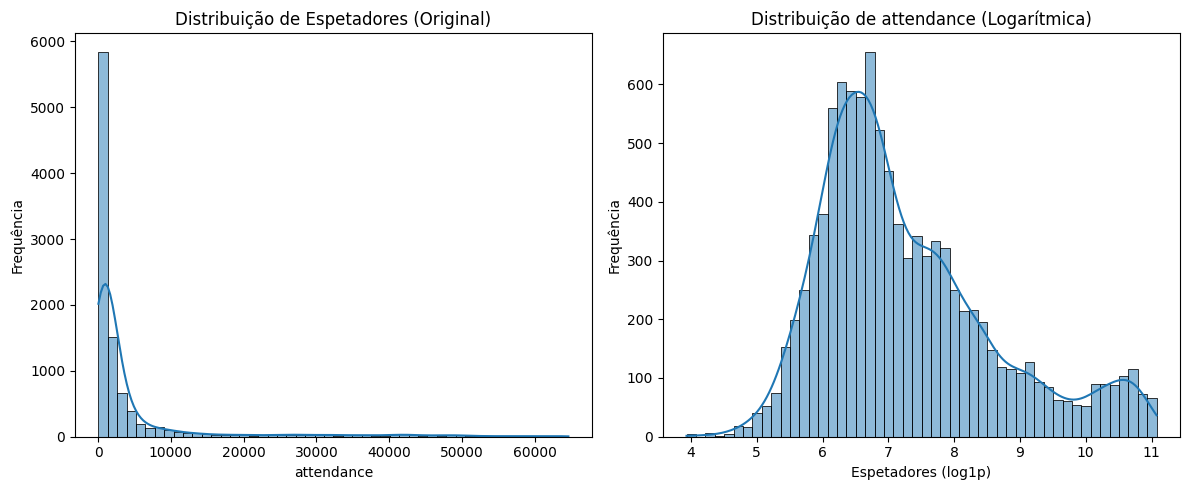


Estatísticas Descritivas para Espetadores (logarítmica):
         attendance  attendance_log
count   9997.000000     9997.000000
mean    4579.183355        7.268538
std    10049.022609        1.340290
min       50.000000        3.931826
25%      553.000000        6.317165
50%     1015.000000        6.923629
75%     2818.000000        7.944137
max    64591.000000       11.075846


In [18]:
#NORMALIZAÇÃO DA VARIÁVEL Espetadores

if df_processed is not None and not df_processed.empty:
    # Aplicar a transformação logarítmica (log1p para lidar com zeros)
    df_processed['attendance_log'] = np.log1p(df_processed['attendance'])
    logger_main.info("Transformação logarítmica aplicada à coluna 'attendance'.")
    print("\nPrimeiras linhas do DataFrame com a coluna 'attendance_log':")
    print(df_processed[['attendance', 'attendance_log']].head())

    # Opcional: Visualizar a distribuição antes e depois da transformação logarítmica
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(df_processed['attendance'], kde=True, bins=50) # type: ignore
    plt.title('Distribuição de Espetadores (Original)')
    plt.xlabel('attendance')
    plt.ylabel('Frequência')

    plt.subplot(1, 2, 2)
    sns.histplot(df_processed['attendance_log'], kde=True, bins=50) # type: ignore
    plt.title('Distribuição de attendance (Logarítmica)')
    plt.xlabel('Espetadores (log1p)')
    plt.ylabel('Frequência')

    plt.tight_layout()
    plt.show()

    # Opcional: Verificar estatísticas descritivas após a transformação
    print("\nEstatísticas Descritivas para Espetadores (logarítmica):")
    print(df_processed[['attendance', 'attendance_log']].describe())


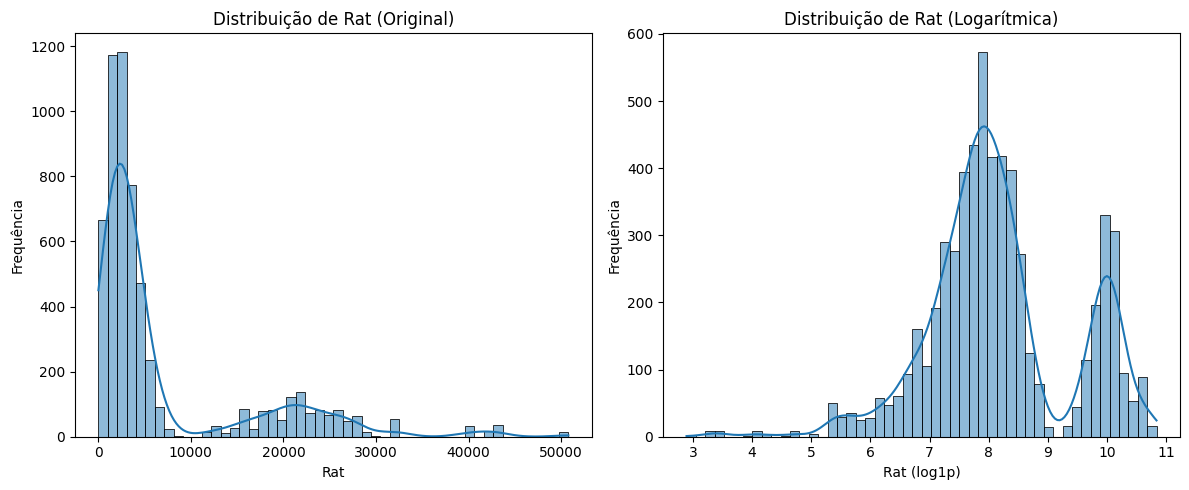

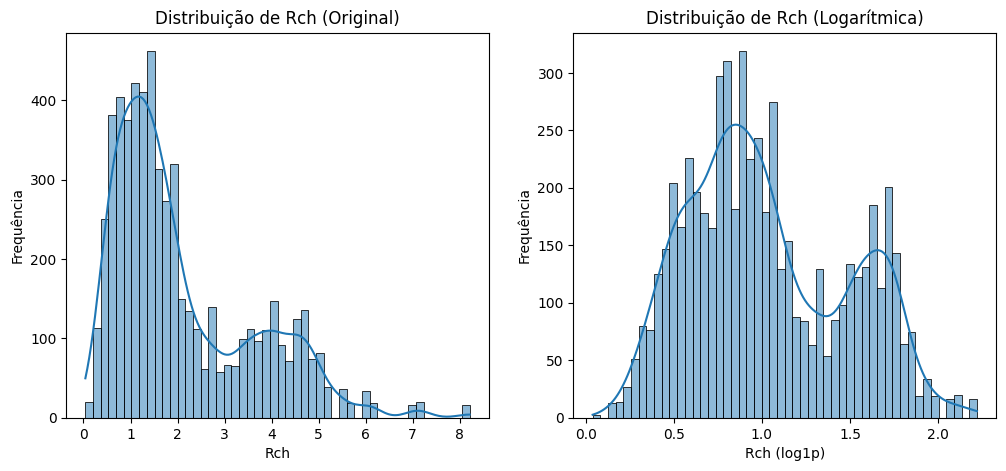

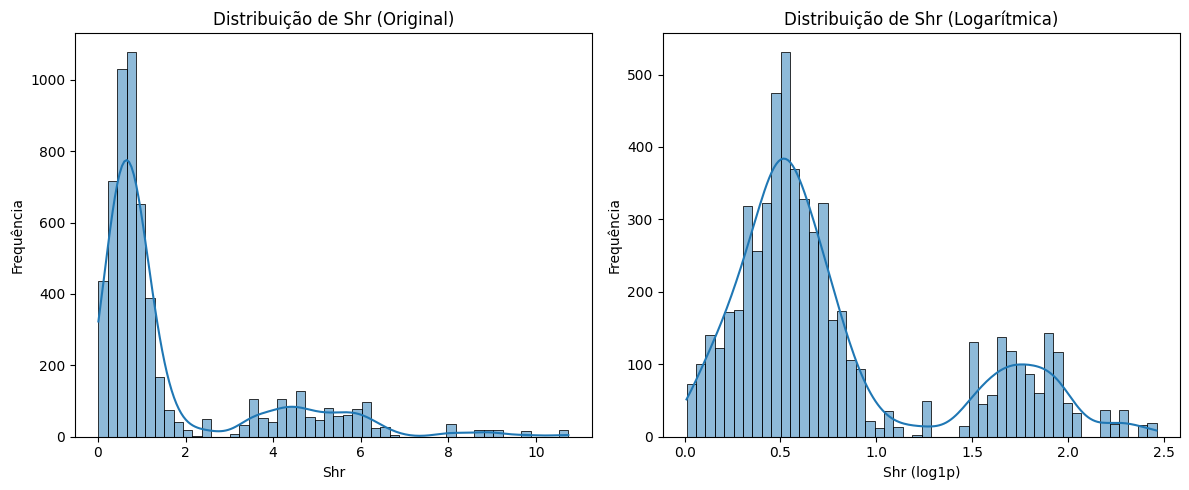

In [19]:
#NORMALIZAÇÃO DAS VARIÁVEIS RAT, RCH E SHR

df_processed_filtered = df_processed.query('rat_clean != 0 & rch_clean != 0 & shr_clean != 0')

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed_filtered['rat_clean'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Rat (Original)')
plt.xlabel('Rat')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['rat_log'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Rat (Logarítmica)')
plt.xlabel('Rat (log1p)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1) 
sns.histplot(df_processed_filtered['rch_clean'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Rch (Original)')
plt.xlabel('Rch')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['rch_log'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Rch (Logarítmica)')
plt.xlabel('Rch (log1p)')
plt.ylabel('Frequência')
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_processed_filtered['shr_clean'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Shr (Original)')
plt.xlabel('Shr')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_processed_filtered['shr_log'], kde=True, bins=50) # type: ignore
plt.title('Distribuição de Shr (Logarítmica)')
plt.xlabel('Shr (log1p)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

Separate into two different datasets

In [20]:
df_processed['total_distance'] = (
        df_processed['home_game_distance'] +
        df_processed['away_game_distance'])

df_betclic = df_processed[df_processed['league'] == 'Liga Portugal Betclic'].copy()
df_meu_super = df_processed[df_processed['league'] == 'Liga Portugal Meu Super'].copy()

print("DataFrame for Liga Portugal Betclic:")
print(df_betclic.head())

print("\nDataFrame for Liga Portugal Meu Super:")
print(df_meu_super.head())

DataFrame for Liga Portugal Betclic:
     season                 league           league_clean  \
327  201213  Liga Portugal Betclic  liga_portugal_betclic   
328  201213  Liga Portugal Betclic  liga_portugal_betclic   
329  201213  Liga Portugal Betclic  liga_portugal_betclic   
330  201213  Liga Portugal Betclic  liga_portugal_betclic   
331  201213  Liga Portugal Betclic  liga_portugal_betclic   

                     date_time      home_team home_team_clean      away_team  \
327  2012-08-17 20:15:00+00:00   SC Olhanense    sc_olhanense  Estoril Praia   
328  2012-08-18 18:14:00+00:00     Rio Ave FC      rio_ave_fc    Marítimo M.   
329  2012-08-18 20:15:00+00:00     SL Benfica      sl_benfica       SC Braga   
330  2012-08-19 16:00:00+00:00    CD Nacional     cd_nacional     Vitória FC   
331  2012-08-19 18:00:00+00:00  FC P.Ferreira    fc_pferreira  Moreirense FC   

    away_team_clean  round  attendance  ...  final_slot  \
327   estoril_praia    1.0         516  ...  4 20:15:00 

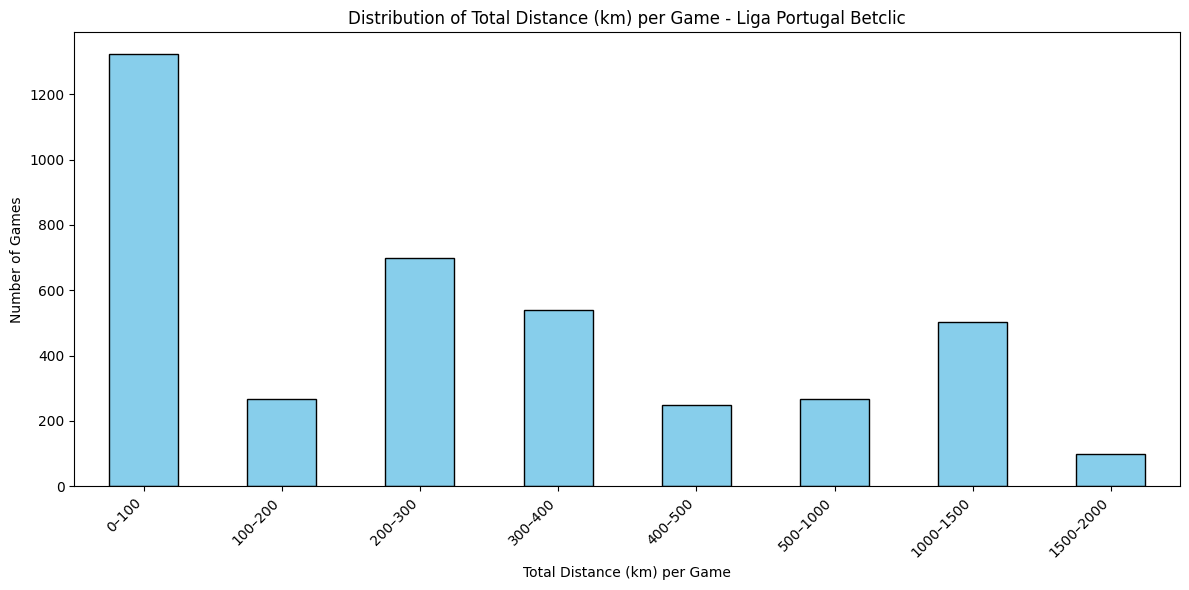

Total distance (all games): 1,588,551 km
Average distance per game: 402.4 km


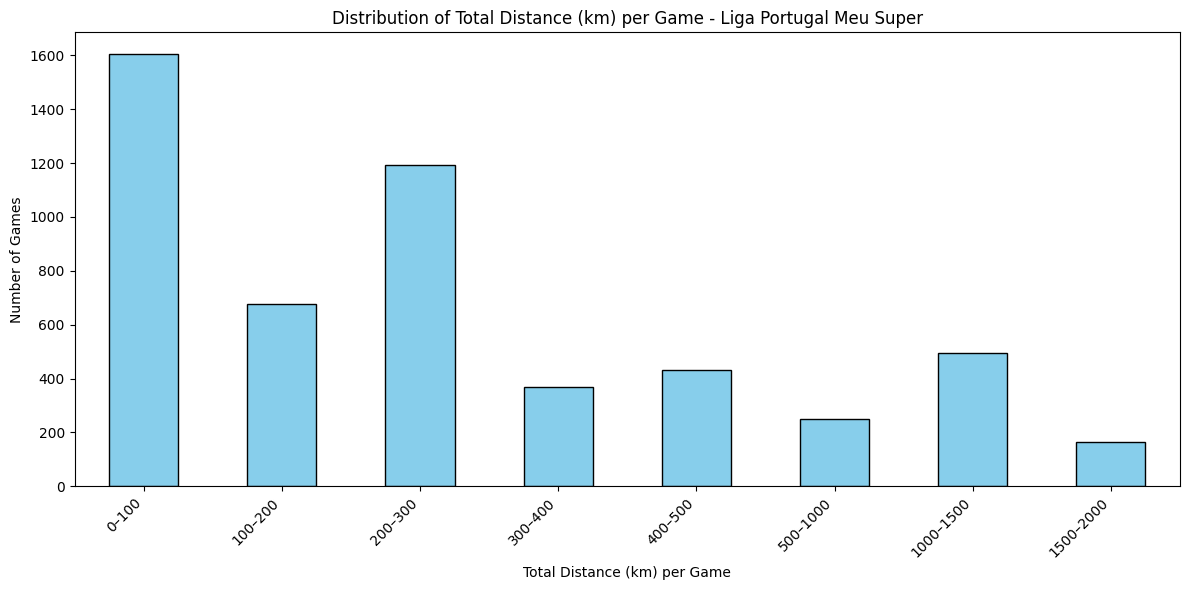

Total distance (all games): 1,875,110 km
Average distance per game: 362.0 km


In [ ]:
def plot_distance_distribution(df, title):
    
    df_games = df_processed.loc[df.index].copy()
    
    bins = [0, 100, 200, 300, 400, 500, 1000, 1500, 2000]
    labels = ['0–100', '100–200', '200–300', '300–400', '400–500', '500–1000', '1000–1500', '1500–2000']
    df_games['total_distance_bin'] = pd.cut(df_games['total_distance'], bins=bins, labels=labels, right=False)

    
    distancia_counts = df_games['total_distance_bin'].value_counts().sort_index()

    
    plt.figure(figsize=(12, 6))
    distancia_counts.plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(title)
    plt.xlabel('Total Distance (km) per Game')
    plt.ylabel('Number of Games')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # (opcional) mostrar estatísticas resumidas
    total = df_games['total_distance'].sum()
    mean = df_games['total_distance'].mean()
    print(f"Total distance (all games): {total:,.0f} km")
    print(f"Average distance per game: {mean:,.1f} km")



plot_distance_distribution(df_betclic, 'Distribution of Total Distance (km) per Game - Liga Portugal Betclic')
plot_distance_distribution(df_meu_super, 'Distribution of Total Distance (km) per Game - Liga Portugal Meu Super')

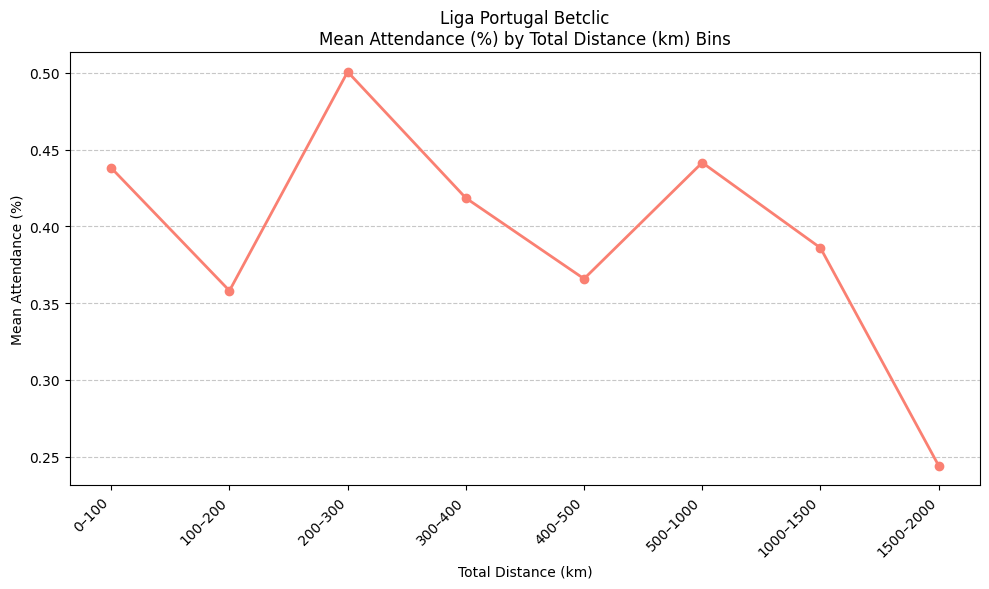

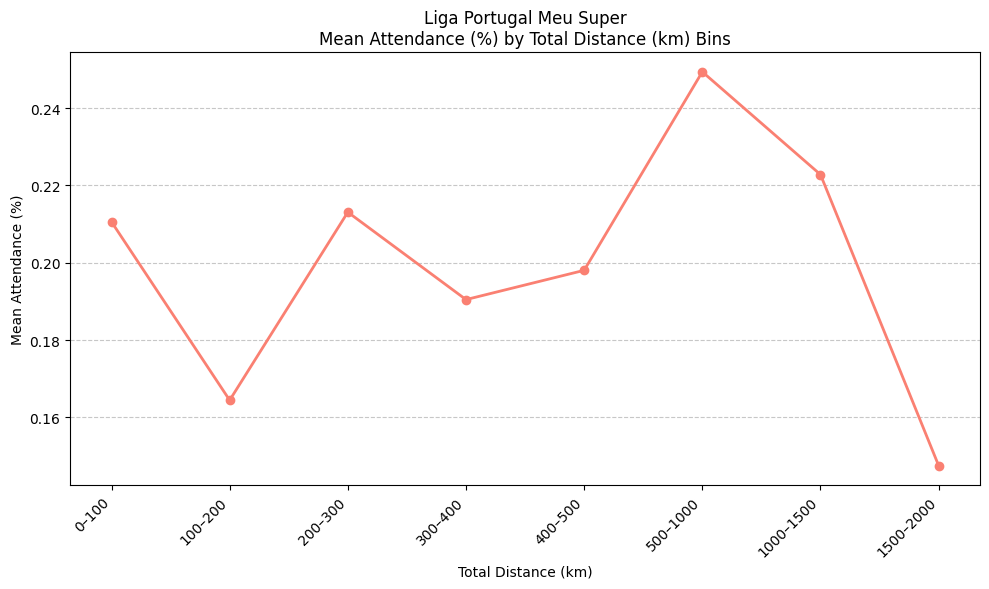

In [37]:
def plot_mean_attendance_by_distance(df, title):
    """
    Plots the mean attendance rate (%) per total distance bin.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing 'total_distance' and 'attendance_rate' columns.
    title : str
        Title for the plot (e.g., competition name).

    Returns
    -------
    None
        Displays a line chart of mean attendance per distance bin.
    """

    # 1) Define distance bins and labels
    bins = [0, 100, 200, 300, 400, 500, 1000, 1500, 2000]
    labels = ['0–100', '100–200', '200–300', '300–400', '400–500',
              '500–1000', '1000–1500', '1500–2000']

    df = df.copy()
    df['total_distance_bin'] = pd.cut(
        df['total_distance'],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    # 2) Compute mean attendance per bin
    mean_attendance_by_bin = (
        df.groupby('total_distance_bin', observed=False)['attendance_rate']
        .mean()
        .reindex(labels)
    )

    # 3) Plot the line chart
    plt.figure(figsize=(10, 6))
    plt.plot(
        labels,
        mean_attendance_by_bin,
        marker='o',
        linestyle='-',
        color='salmon',
        linewidth=2
    )

    # 4) Customize the plot
    plt.title(f'{title}\nMean Attendance (%) by Total Distance (km) Bins')
    plt.xlabel('Total Distance (km)')
    plt.ylabel('Mean Attendance (%)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_mean_attendance_by_distance(df_betclic, 'Liga Portugal Betclic')
plot_mean_attendance_by_distance(df_meu_super, 'Liga Portugal Meu Super')


In [41]:
def top5_pairs_by_distance_bin(df):
    """
    Returns the top 5 unique team pairs (home–away) in each total distance bin
    based on mean attendance rate.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing at least the following columns:
        ['home_team', 'away_team', 'attendance_rate', 'total_distance']

    Returns
    -------
    pandas.DataFrame
        A DataFrame with the top 5 team pairs (by mean attendance_rate) per distance bin.
    """

    # Define distance bins and labels
    bins = [0, 100, 200, 300, 400, 500, 1000, 1500, 2000]
    labels = ['0–100', '100–200', '200–300', '300–400', '400–500',
              '500–1000', '1000–1500', '1500–2000']

    df = df.copy()
    df['total_distance_bin'] = pd.cut(
        df['total_distance'],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    # Normalize team pairs so (Home, Away) and (Away, Home) are treated as the same
    df['team_pair'] = df.apply(
        lambda row: tuple(sorted([row['home_team'], row['away_team']])),
        axis=1
    )

    # Compute mean attendance per team pair within each bin
    mean_attendance_pairs = (
        df.groupby(['total_distance_bin', 'team_pair'], observed=False)['attendance_rate']
        .mean()
        .reset_index()
    )

    # Get top 5 pairs per distance bin
    top5_pairs = (
        mean_attendance_pairs
        .sort_values(['total_distance_bin', 'attendance_rate'], ascending=[True, False])
        .groupby('total_distance_bin', observed=False)
        .head(5)
        .reset_index(drop=True)
    )

    return top5_pairs

    
top5_pairs_betclic = top5_pairs_by_distance_bin(df_betclic)
top5_pairs_meu_super = top5_pairs_by_distance_bin(df_meu_super)

print("\nTop 5 Team Pairs by Distance Bin - Liga Portugal Betclic:")
print(top5_pairs_betclic)

print("\nTop 5 Team Pairs by Distance Bin - Liga Portugal Meu Super:")
print(top5_pairs_meu_super)


Top 5 Team Pairs by Distance Bin - Liga Portugal Betclic:
   total_distance_bin                      team_pair  attendance_rate
0               0–100      (Marítimo M., U. Madeira)         0.981750
1               0–100      (Casa Pia AC, SL Benfica)         0.943300
2               0–100  (Estrela Amadora, SL Benfica)         0.935125
3               0–100        (CD Feirense, FC Porto)         0.914417
4               0–100    (Estoril Praia, SL Benfica)         0.884110
5             100–200      (Casa Pia AC, SL Benfica)         1.000000
6             100–200          (FC Porto, GD Chaves)         0.762730
7             100–200    (Portimonense, Sporting CP)         0.676836
8             100–200     (Portimonense, SL Benfica)         0.661379
9             100–200     (A. Académica, SL Benfica)         0.575725
10            200–300              (AFS, SL Benfica)         0.890100
11            200–300      (CD Feirense, SL Benfica)         0.889517
12            200–300         (

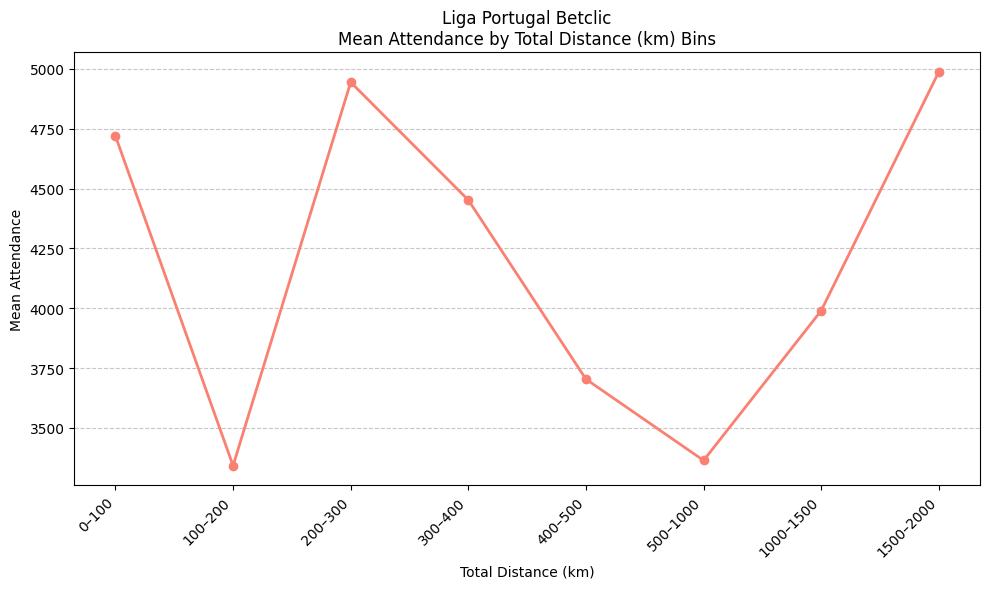

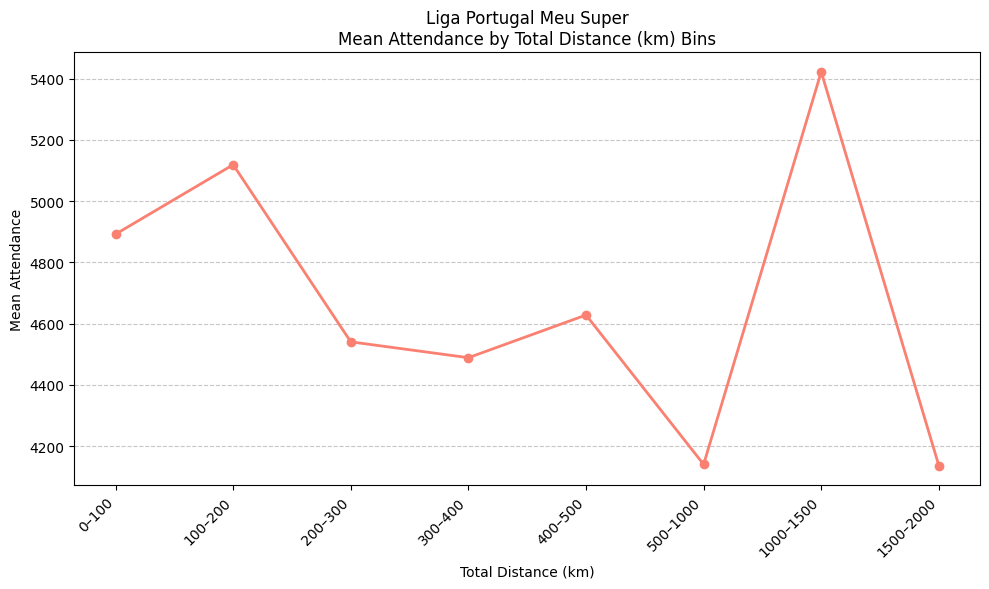

In [40]:
def plot_mean_attendance_by_distance(df, title):
    """
    Plots the mean attendance rate (%) per total distance bin.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing 'total_distance' and 'attendance_rate' columns.
    title : str
        Title for the plot (e.g., competition name).

    Returns
    -------
    None
        Displays a line chart of mean attendance per distance bin.
    """

    # 1) Define distance bins and labels
    bins = [0, 100, 200, 300, 400, 500, 1000, 1500, 2000]
    labels = ['0–100', '100–200', '200–300', '300–400', '400–500',
              '500–1000', '1000–1500', '1500–2000']

    df = df.copy()
    df['total_distance_bin'] = pd.cut(
        df['total_distance'],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    # 2) Compute mean attendance per bin
    mean_attendance_by_bin = (
        df.groupby('total_distance_bin', observed=False)['attendance']
        .mean()
        .reindex(labels)
    )

    # 3) Plot the line chart
    plt.figure(figsize=(10, 6))
    plt.plot(
        labels,
        mean_attendance_by_bin,
        marker='o',
        linestyle='-',
        color='salmon',
        linewidth=2
    )

    # 4) Customize the plot
    plt.title(f'{title}\nMean Attendance by Total Distance (km) Bins')
    plt.xlabel('Total Distance (km)')
    plt.ylabel('Mean Attendance')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_mean_attendance_by_distance(df_betclic, 'Liga Portugal Betclic')
plot_mean_attendance_by_distance(df_meu_super, 'Liga Portugal Meu Super')

In [44]:
def top5_pairs_by_distance_bin(df):
    """
    Returns the top 5 unique team pairs (home–away) in each total distance bin
    based on mean attendance, including the main stadium name.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing at least the following columns:
        ['home_team', 'away_team', 'stadium', 'attendance', 'total_distance']

    Returns
    -------
    pandas.DataFrame
        A DataFrame with the top 5 team pairs per distance bin, including stadium name
        and mean attendance.
    """

    # Define distance bins and labels
    bins = [0, 100, 200, 300, 400, 500, 1000, 1500, 2000]
    labels = ['0–100', '100–200', '200–300', '300–400', '400–500',
              '500–1000', '1000–1500', '1500–2000']

    df = df.copy()
    df['total_distance_bin'] = pd.cut(
        df['total_distance'],
        bins=bins,
        labels=labels,
        right=False,
        include_lowest=True
    )

    # Normalize team pairs so (Home, Away) and (Away, Home) are treated as the same
    df['team_pair'] = df.apply(
        lambda row: tuple(sorted([row['home_team'], row['away_team']])),
        axis=1
    )

    # Compute mean attendance per team pair and stadium within each bin
    mean_attendance_pairs = (
        df.groupby(['total_distance_bin', 'team_pair', 'game_stadium'], observed=False)['attendance']
        .mean()
        .reset_index()
    )

    # Get top 5 pairs per distance bin
    top5_pairs = (
        mean_attendance_pairs
        .sort_values(['total_distance_bin', 'attendance'], ascending=[True, False])
        .groupby('total_distance_bin', observed=False)
        .head(5)
        .reset_index(drop=True)
    )

    return top5_pairs

    
top5_pairs_betclic = top5_pairs_by_distance_bin(df_betclic)
top5_pairs_meu_super = top5_pairs_by_distance_bin(df_meu_super)

print("\nTop 5 Team Pairs by Distance Bin - Liga Portugal Betclic:")
print(top5_pairs_betclic)

print("\nTop 5 Team Pairs by Distance Bin - Liga Portugal Meu Super:")
print(top5_pairs_meu_super)


Top 5 Team Pairs by Distance Bin - Liga Portugal Betclic:
   total_distance_bin                         team_pair  \
0               0–100              (AFS, Moreirense FC)   
1               0–100      (Gil Vicente FC, Rio Ave FC)   
2               0–100                   (AFS, SC Braga)   
3               0–100              (AFS, Moreirense FC)   
4               0–100                   (AFS, SC Braga)   
5             100–200            (FC Arouca, GD Chaves)   
6             100–200             (B SAD, Portimonense)   
7             100–200        (SC Olhanense, Vitória FC)   
8             100–200          (Boavista FC, GD Chaves)   
9             100–200        (A. Académica, SL Benfica)   
10            200–300                (AFS, Sporting CP)   
11            200–300           (Beira-Mar, Vitória FC)   
12            200–300                 (AFS, SL Benfica)   
13            200–300      (Casa Pia AC, FC P.Ferreira)   
14            200–300                (B SAD, FC Arouca) 

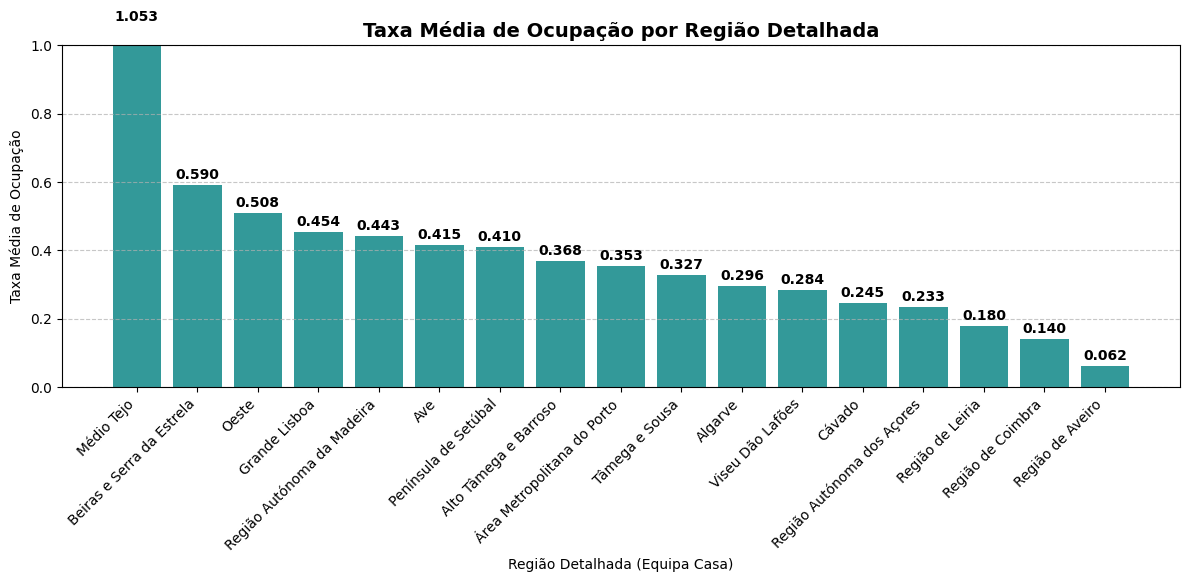

Taxa Média de Ocupação por Região (ordenada):
Médio Tejo: 1.053
Beiras e Serra da Estrela: 0.590
Oeste: 0.508
Grande Lisboa: 0.454
Região Autónoma da Madeira: 0.443
Ave: 0.415
Península de Setúbal: 0.410
Alto Tâmega e Barroso: 0.368
Área Metropolitana do Porto: 0.353
Tâmega e Sousa: 0.327
Algarve: 0.296
Viseu Dão Lafões: 0.284
Cávado: 0.245
Região Autónoma dos Açores: 0.233
Região de Leiria: 0.180
Região de Coimbra: 0.140
Região de Aveiro: 0.062


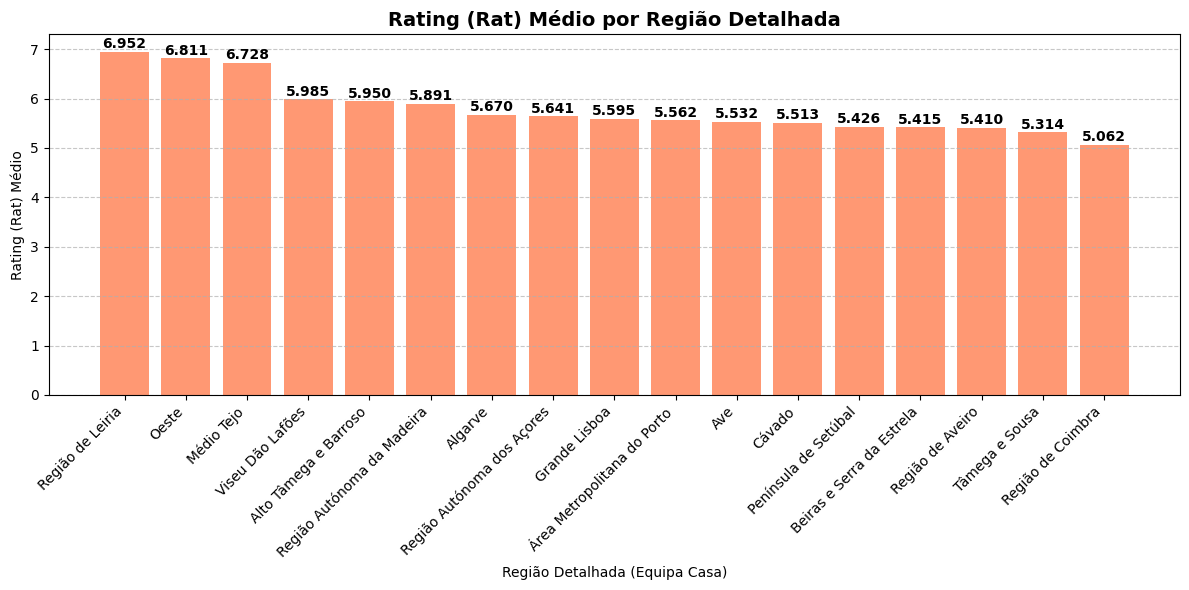


Rating (Rat) Médio por Região (ordenado):
Região de Leiria: 6.952
Oeste: 6.811
Médio Tejo: 6.728
Viseu Dão Lafões: 5.985
Alto Tâmega e Barroso: 5.950
Região Autónoma da Madeira: 5.891
Algarve: 5.670
Região Autónoma dos Açores: 5.641
Grande Lisboa: 5.595
Área Metropolitana do Porto: 5.562
Ave: 5.532
Cávado: 5.513
Península de Setúbal: 5.426
Beiras e Serra da Estrela: 5.415
Região de Aveiro: 5.410
Tâmega e Sousa: 5.314
Região de Coimbra: 5.062


In [414]:
# Taxa de Ocupação Média por Região Detalhada (ordenada do maior para o menor)
mean_taxa_ocupacao = df_processed.groupby('Regiao_Detalhada_Casa')['TaxaOcupacao_decimal'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(mean_taxa_ocupacao)), mean_taxa_ocupacao.values, color='teal', alpha=0.8)
plt.title('Taxa Média de Ocupação por Região Detalhada', fontsize=14, fontweight='bold')
plt.xlabel('Região Detalhada (Equipa Casa)')
plt.ylabel('Taxa Média de Ocupação')
plt.xticks(range(len(mean_taxa_ocupacao)), mean_taxa_ocupacao.index, rotation=45, ha='right')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adicionar valores nas barras
for i, v in enumerate(mean_taxa_ocupacao.values):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("Taxa Média de Ocupação por Região (ordenada):")
for regiao, taxa in mean_taxa_ocupacao.items():
    print(f"{regiao}: {taxa:.3f}")

# Rating (Rat) Médio por Região Detalhada (ordenado do maior para o menor)
mean_rat = df_processed.groupby('Regiao_Detalhada_Casa')['Rat_log'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(mean_rat)), mean_rat.values, color='coral', alpha=0.8)
plt.title('Rating (Rat) Médio por Região Detalhada', fontsize=14, fontweight='bold')
plt.xlabel('Região Detalhada (Equipa Casa)')
plt.ylabel('Rating (Rat) Médio')
plt.xticks(range(len(mean_rat)), mean_rat.index, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adicionar valores nas barras
for i, v in enumerate(mean_rat.values):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nRating (Rat) Médio por Região (ordenado):")
for regiao, rat in mean_rat.items():
    print(f"{regiao}: {rat:.3f}")

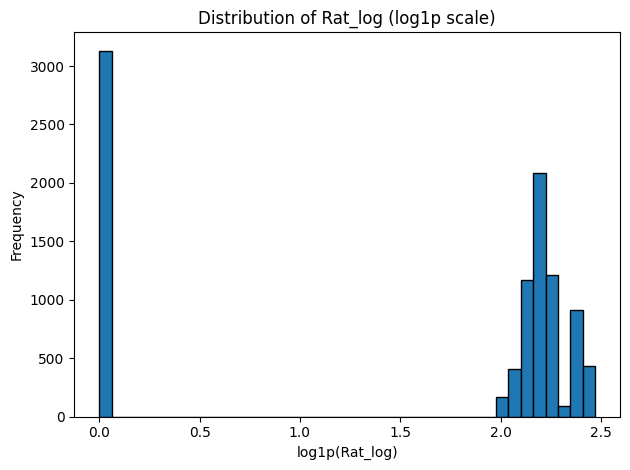

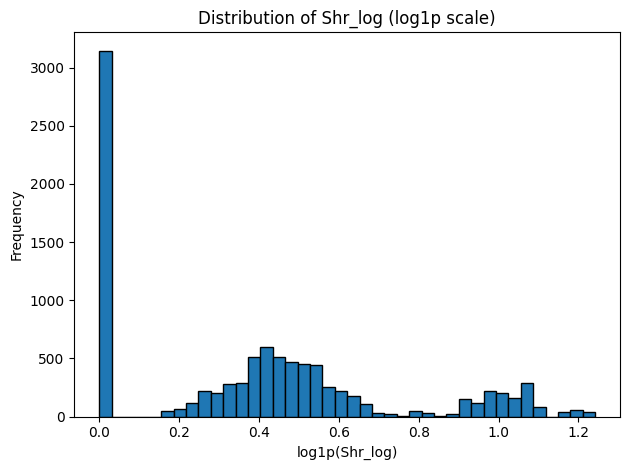

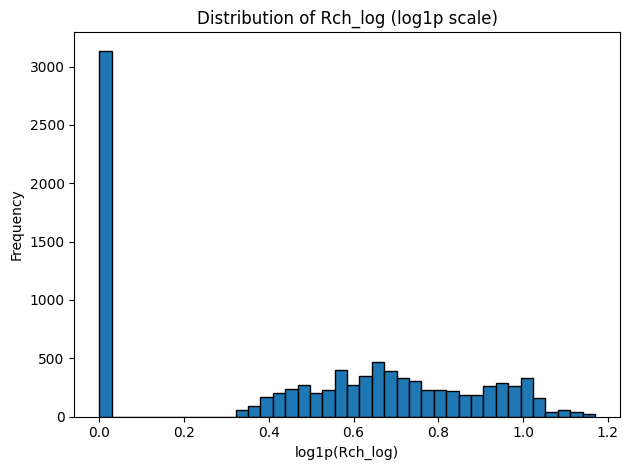

,Metric,Skewness
0,Rat_log,-0.597
1,Shr_log,1.159
2,Rch_log,0.190


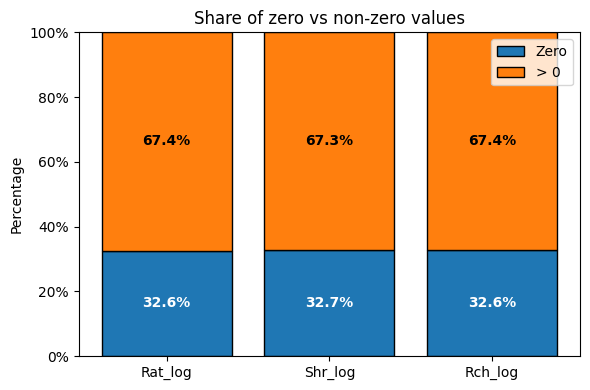

In [415]:
# Histograms (log1p) + Skewness (raw) + Zero vs >0

metrics = ['Rat_log','Shr_log','Rch_log']

# --- Histograms (log1p) and Skewness table (raw) ---
shape_rows = []
for m in metrics:
    data = df_processed[m].dropna().values

    # histograma em escala log1p
    x = np.log1p(data)
    plt.figure()
    plt.hist(x, bins=40, edgecolor='black')
    plt.title(f'Distribution of {m} (log1p scale)')
    plt.xlabel(f'log1p({m})'); plt.ylabel('Frequency')
    plt.tight_layout(); plt.show()

    # Skewness sobre os dados originais
    skew = stats.skew(data, nan_policy='omit')
    shape_rows.append({'Metric': m, 'Skewness': skew})

shape_df = pd.DataFrame(shape_rows).round(3)
display(shape_df)

# --- Stacked bar: share of zero vs non-zero ---
zeros_pct    = [(df_processed[m] == 0).mean()*100 for m in metrics]
nonzeros_pct = [100 - z for z in zeros_pct]

fig, ax = plt.subplots(figsize=(6,4))
xpos = np.arange(len(metrics))
ax.bar(xpos, zeros_pct,    label='Zero', edgecolor='black')
ax.bar(xpos, nonzeros_pct, bottom=zeros_pct, label='> 0', edgecolor='black')

ax.set_xticks(xpos); ax.set_xticklabels(metrics)
ax.set_ylabel('Percentage'); ax.set_title('Share of zero vs non-zero values')
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()

# Anotações dentro das barras
for i, (z, nz) in enumerate(zip(zeros_pct, nonzeros_pct)):
    ax.text(i, z/2,      f'{z:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    ax.text(i, z + nz/2, f'{nz:.1f}%', ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout(); plt.show()

In [416]:
# Audience descriptive statistics — tables only

cols = ['Rat_log','Shr_log','Rch_log']

# Descriptive table with Zero_%
desc = df_processed[cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc['Zero_%'] = [(df_processed[c] == 0).mean() * 100 for c in cols]
desc = desc.rename(columns={
    'count':'Count','mean':'Mean','std':'Std','min':'Min',
    '25%':'Q1','50%':'Median','75%':'Q3','max':'Max'
})
display(desc.round(3))

# Median & IQR table
q1  = df_processed[cols].quantile(0.25)
med = df_processed[cols].median()
q3  = df_processed[cols].quantile(0.75)

iqr_tab = pd.DataFrame({'Q1': q1, 'Median': med, 'Q3': q3, 'IQR': q3 - q1})
display(iqr_tab.round(3))

# Histograms in log1p scale
plot_hist = False
if plot_hist:
    for var in cols:
        x = np.log1p(df_processed[var].dropna())  # safe log: log(1+x)
        plt.figure()
        plt.hist(x, bins=40, edgecolor='black')
        plt.title(f'Distribution of {var} (log1p scale)')
        plt.xlabel(f'log1p({var})'); plt.ylabel('Frequency')
        plt.tight_layout(); plt.show()

,Count,Mean,Std,Min,Q1,Median,Q3,Max,Zero_%
Rat_log,9614.0,5.604,3.985,0.0,0.0,7.663,8.317,10.835,32.577
Shr_log,9614.0,0.567,0.592,0.0,0.0,0.489,0.732,2.463,32.713
Rch_log,9614.0,0.729,0.609,0.0,0.0,0.772,1.160,2.220,32.629


,Q1,Median,Q3,IQR
Rat_log,0.0,7.663,8.317,8.317
Shr_log,0.0,0.489,0.732,0.732
Rch_log,0.0,0.772,1.160,1.160


Resume as métricas Rat, Shr, Rch (count, média, desvio-padrão, min/percentis/max) e calcula % de zeros.

Amostra: n = 8 050 registos nas três métricas (Rat, Shr, Rch).

Zero-inflation marcada: cerca de 72% dos valores são 0 em todas as métricas (Zero_% ≈ 71,6%).

Tendência central muito baixa: Q1 = 0 e Mediana = 0 ⇒ pelo menos 50% dos jogos têm valor nulo; até ao 75.º percentil (Q3) os valores continuam baixos:

Rat Q3 = 5,96, Shr Q3 = 0,18, Rch Q3 = 0,50.

Dispersão/assimetria: Média bem acima de Mediana e Desvio-padrão elevado (p.ex., Rat Mean 17,8 vs Std 55,2) ⇒ cauda direita longa com poucos casos muito altos (máx. Rat 583,53, Shr 14,57, Rch 9,63).

IQR: como Q1=0, o IQR = Q3 − Q1 coincide com Q3 (Rat 5,96, Shr 0,18, Rch 0,50) e resume a variação “típica” acima de zero.

,Weekday (0=Mon … 6=Sun),Rat_log,Shr_log,Rch_log,N
0,0,6.040,0.617,0.786,671
1,1,5.251,0.476,0.796,185
2,2,4.889,0.534,0.667,912
3,3,5.346,0.613,0.693,164
4,4,5.867,0.558,0.740,681
5,5,5.755,0.575,0.755,2823
6,6,5.570,0.565,0.713,4178


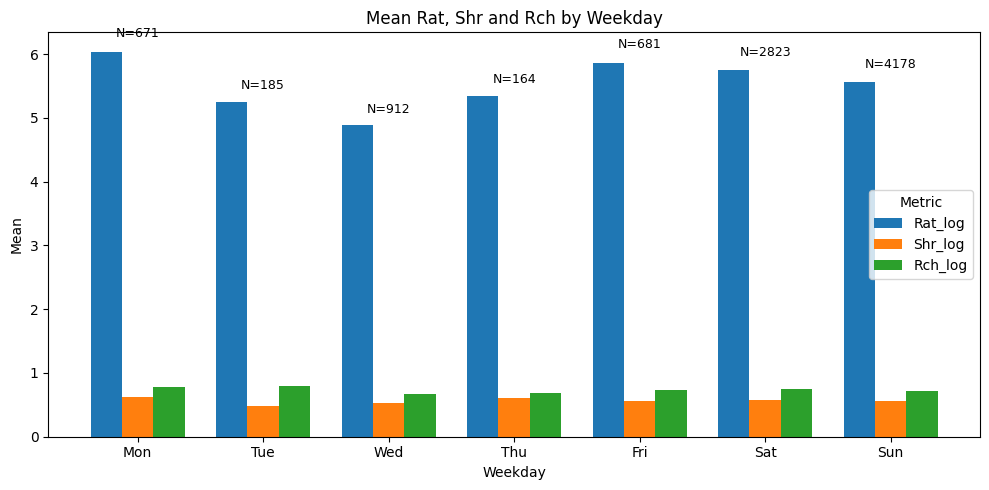

In [417]:
# Weekday effect — Means (with day names + N per day)

metrics = ['Rat_log','Shr_log','Rch_log']

# Means by weekday + counts
mean_tab = df_processed.groupby('Weekday_num')[metrics].mean().reset_index()
count_tab = df_processed.groupby('Weekday_num').size().reset_index(name='N')

mean_tab_en = mean_tab.merge(count_tab, on='Weekday_num', how='left')
mean_tab_en = mean_tab_en.rename(columns={'Weekday_num': 'Weekday (0=Mon … 6=Sun)'})
display(mean_tab_en.round(3))

# Bar chart (grouped) + annotate N
x = mean_tab['Weekday_num'].values
width = 0.25
fig, ax = plt.subplots(figsize=(10,5))
for i, m in enumerate(metrics):
    ax.bar(x + (i-1)*width, mean_tab[m].values, width, label=m)

# Day names (EN)
day_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
ax.set_title('Mean Rat, Shr and Rch by Weekday')
ax.set_xlabel('Weekday'); ax.set_ylabel('Mean')
ax.set_xticks(x); ax.set_xticklabels([day_names[int(v)] for v in x])
ax.legend(title='Metric')

# Annotate N on top (centered above the group of bars)
n_map = dict(zip(count_tab['Weekday_num'], count_tab['N']))
for xi in x:
    ax.text(xi, max(mean_tab.loc[mean_tab['Weekday_num']==xi, metrics].values.flatten())*1.03,
            f"N={n_map.get(int(xi),0)}", ha='center', va='bottom', fontsize=9)

plt.tight_layout(); plt.show()

Cria Weekday_num (0=Seg … 6=Dom), calcula a média de Rat, Shr, Rch por dia e exibe tabela + gráfico de barras (descrição; sem testes).

**Resultados:**

Segunda (0): maiores médias — Rat 25,185, Shr 0,565, Rch 0,874.

Sábado (5) ≳ Sexta (4) nas três métricas (ex.: Rat 20,508 vs 19,318; Shr 0,536 vs 0,444; Rch 0,599 vs 0,588).

Domingo (6): menores médias — Rat 14,225, Shr 0,338, Rch 0,459.

Apenas surgem os dias 0, 4, 5, 6 porque são os que existem na amostra (os restantes não tiveram jogos/registos).

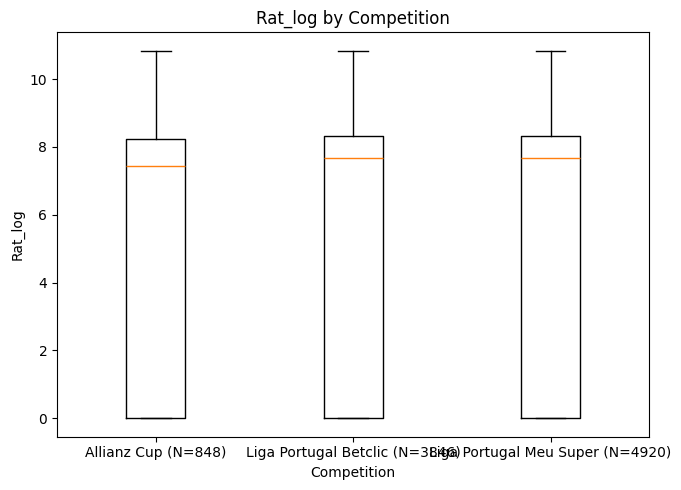

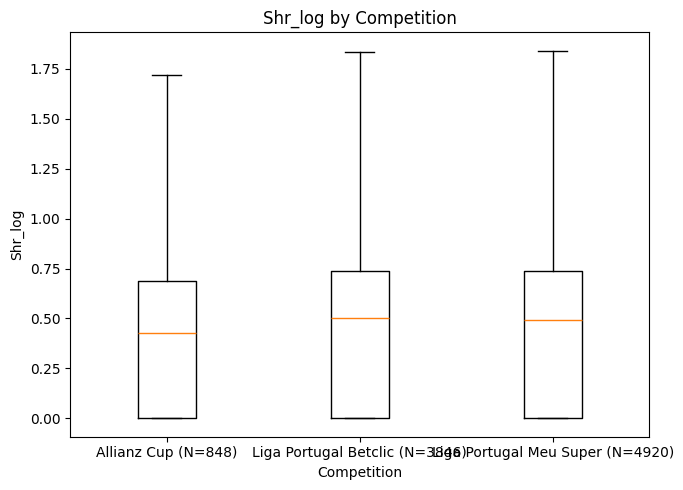

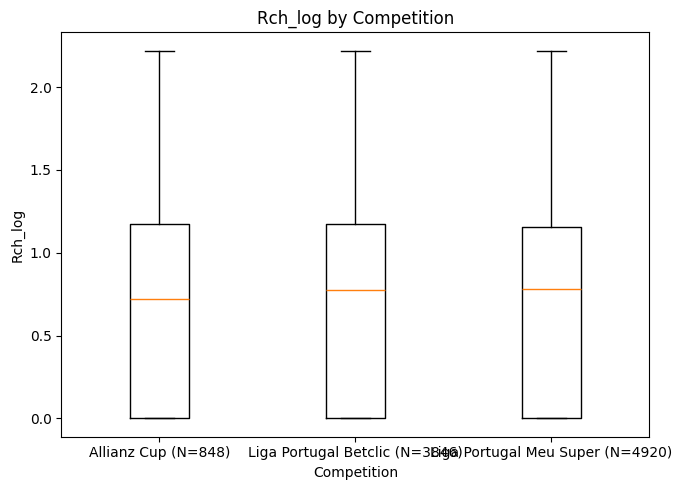

In [418]:
# Competition — Boxplots (Rat, Shr, Rch)

assert 'df_processed' in globals(), "Carregue primeiro o DataFrame df_processed."

if 'Competicao' not in df_processed.columns:
    display(pd.DataFrame({'Note': ['Column "Competicao" not found.']}))
else:
    dfc = df_processed.copy().rename(columns={'Competicao': 'Competition'})
    metrics = ['Rat_log', 'Shr_log', 'Rch_log']

    # ordem/labels e N por competição (para contexto no gráfico)
    cnt = dfc['Competition'].value_counts().sort_index()
    comps = cnt.index.tolist()
    labels = [f"{c} (N={cnt[c]})" for c in comps]

    if len(comps) < 2:
        print("Only one competition present; group comparison not applicable.")
    else:
        for var in metrics:
            data = [dfc[dfc['Competition'] == c][var].dropna().values for c in comps]

            plt.figure(figsize=(7,5))
            plt.boxplot(data, showfliers=False)  # oculta outliers para focar na dispersão central
            plt.title(f'{var} by Competition')
            plt.xlabel('Competition'); plt.ylabel(var)
            plt.xticks(range(1, len(comps)+1), labels, rotation=0)
            plt.tight_layout(); plt.show()

Mediana ≈ 0 em ambas as competições (linhas centrais praticamente no zero) ⇒ forte zero-inflation.

Dispersão (IQR) muito maior na Liga Portugal Betclic: as “caixas” (Q1–Q3) de Shr e Rch são visivelmente mais altas do que na Meu Super.
→ Quando há audiência positiva, Betclic atinge valores substancialmente superiores.

Extremos bem mais altos na Betclic (Shr chega a ~1–1,6; Rch ~3+) enquanto na Meu Super permanecem muito baixos.
→ Maior probabilidade de picos na Betclic; valores residuais na 2.ª liga.

Amostras (N): há mais jogos na Meu Super (N=4 598) do que na Betclic (N=3 452), mas isso não explica as diferenças — mesmo com mais jogos, a Meu Super mantém Shr/Rch baixos.

Conclusão

A Liga Portugal Betclic apresenta audiências mais elevadas e mais variáveis (maior IQR e máximos), ao passo que a Liga Portugal Meu Super concentra-se perto de zero.

,Match Type,N
0,Regular,9533
1,Derby,52
2,Classic,29


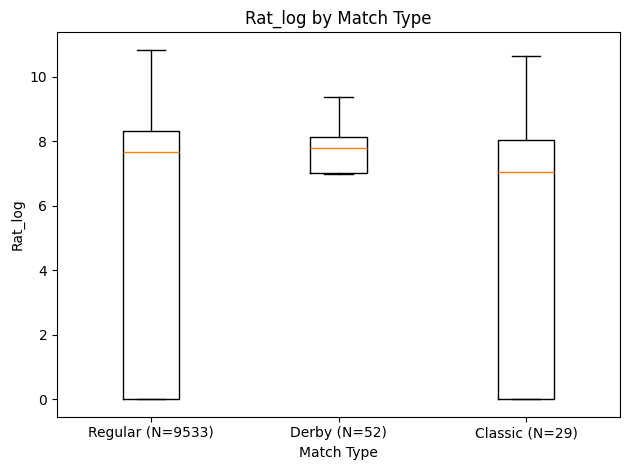

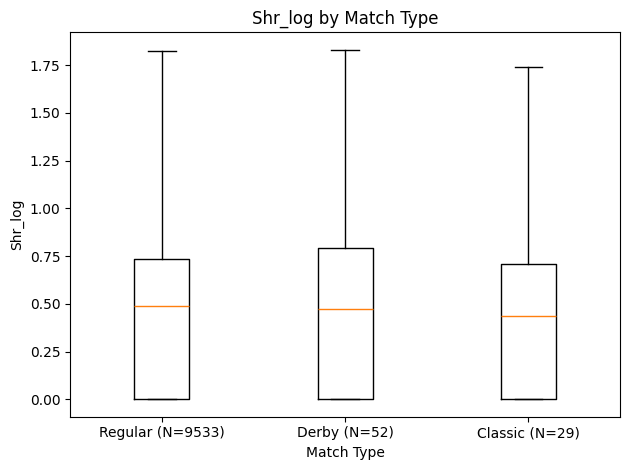

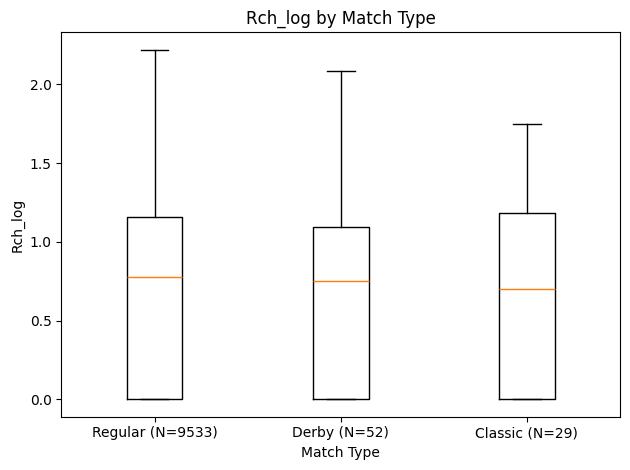

,Match Type,Metric,N,Zero_%,Pos_%,Mean,Median,Q1,Q3,IQR
0,Regular,Rat_log,9533,32.634,67.366,5.600,7.664,0.000,8.319,8.319
1,Regular,Shr_log,9533,32.665,67.335,0.567,0.489,0.000,0.732,0.732
2,Regular,Rch_log,9533,32.665,67.335,0.729,0.775,0.000,1.160,1.160
3,Derby,Rat_log,52,21.154,78.846,6.420,7.802,7.028,8.133,1.105
4,Derby,Shr_log,52,36.538,63.462,0.552,0.472,0.000,0.793,0.793
5,Derby,Rch_log,52,26.923,73.077,0.734,0.751,0.000,1.092,1.092
6,Classic,Rat_log,29,34.483,65.517,5.240,7.051,0.000,8.031,8.031
7,Classic,Shr_log,29,41.379,58.621,0.558,0.438,0.000,0.708,0.708
8,Classic,Rch_log,29,31.034,68.966,0.703,0.703,0.000,1.185,1.185


In [419]:
# Match Type (Classic / Derby / Regular) — Counts + Boxplots + Descriptive table


req = {'EquipaCasa','EquipaFora','Rat_log','Shr_log','Rch_log'}
missing = req.difference(df_processed.columns)
assert not missing, f"Missing columns in df_processed: {sorted(missing)}"

def classify_match_type(casa, fora):
    classics = {('SL Benfica','FC Porto'), ('FC Porto','SL Benfica')}
    derbies  = {
        ('SL Benfica','Sporting CP'), ('Sporting CP','SL Benfica'),
        ('FC Porto','Boavista FC'),   ('Boavista FC','FC Porto')
    }
    return 'Classic' if (casa, fora) in classics else ('Derby' if (casa, fora) in derbies else 'Regular')

df6 = df_processed.copy()
df6['Match_Type'] = df6.apply(lambda r: classify_match_type(r['EquipaCasa'],
                                                            r['EquipaFora']), axis=1)

# Counts
cnt = (df6['Match_Type'].value_counts(dropna=False)
       .rename_axis('Match Type').reset_index(name='N'))
display(cnt)

# Fixed order and labels with N
types_order = ['Regular','Derby','Classic']
present = [t for t in types_order if t in df6['Match_Type'].unique()]
n_map = dict(zip(cnt['Match Type'], cnt['N']))

if len(present) < 2:
    print("Only one match type present; group comparison not applicable.")
else:
    # Boxplots per metric (hide outliers to focus on central spread)
    for var in ['Rat_log','Shr_log','Rch_log']:
        data = [df6[df6['Match_Type']==t][var].dropna().values for t in present]
        plt.figure()
        plt.boxplot(data, showfliers=False)
        plt.title(f'{var} by Match Type')
        plt.xlabel('Match Type'); plt.ylabel(var)
        plt.xticks(range(1, len(present)+1), [f'{t} (N={n_map.get(t,0)})' for t in present])
        plt.tight_layout(); plt.show()

    # Descriptive table per match type (Mean/Median/Q1/Q3/IQR/Zero_%/Pos_%/N)
    rows = []
    for var in ['Rat_log','Shr_log','Rch_log']:
        g = df6.groupby('Match_Type')[var]
        tmp = pd.DataFrame({
            'Match Type': g.mean().index,
            'Metric': var,
            'N': g.count().values,
            'Zero_%': g.apply(lambda s: (s==0).mean()*100).values,
            'Pos_%':  g.apply(lambda s: (s>0).mean()*100).values,
            'Mean':   g.mean().values,
            'Median': g.median().values,
            'Q1':     g.quantile(0.25).values,
            'Q3':     g.quantile(0.75).values
        })
        tmp['IQR'] = tmp['Q3'] - tmp['Q1']
        rows.append(tmp)
    desc_mt = (pd.concat(rows, ignore_index=True)
                 .set_index(['Match Type','Metric'])
                 .loc[present]  # aplica ordem
                 .reset_index()
                 .round(3))
    display(desc_mt)

- Apago ou não esta análise?
**Amostra muito desequilibrada:** Regular n=7 984, Derby n=42, Classic n=24.

Níveis típicos (mediana/IQR): a mediana é ≈0 nos três tipos (muitos zeros), mas Derby e Classic exibem IQR muito maior do que Regular. Isto indica que, quando há audiência >0, tende a ser bastante mais alta nos jogos especiais.

,Season,Metric,N,Zero_%,Mean,Median,Q3
0,2020/21,Rat_log,658,29.179,6.014,7.833,8.530
10,2020/21,Rch_log,658,29.635,0.799,0.861,1.261
5,2020/21,Shr_log,658,32.675,0.606,0.525,0.793
1,2021/22,Rat_log,648,32.253,5.595,7.657,8.283
11,2021/22,Rch_log,648,32.407,0.719,0.756,1.163
6,2021/22,Shr_log,648,29.938,0.597,0.501,0.767
2,2022/23,Rat_log,675,21.037,6.447,7.778,8.295
12,2022/23,Rch_log,675,21.185,0.821,0.852,1.224
7,2022/23,Shr_log,675,21.778,0.567,0.525,0.713
3,2023/24,Rat_log,649,14.484,7.362,8.121,9.683


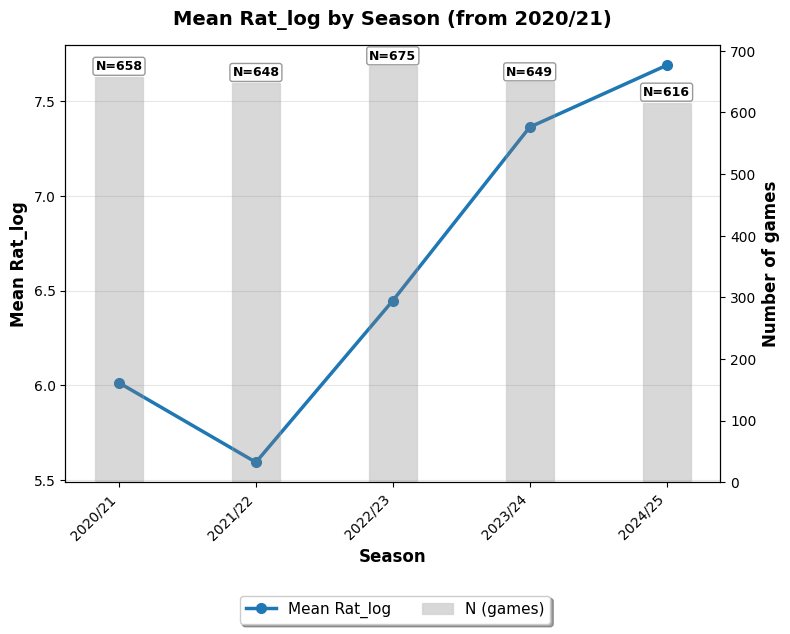

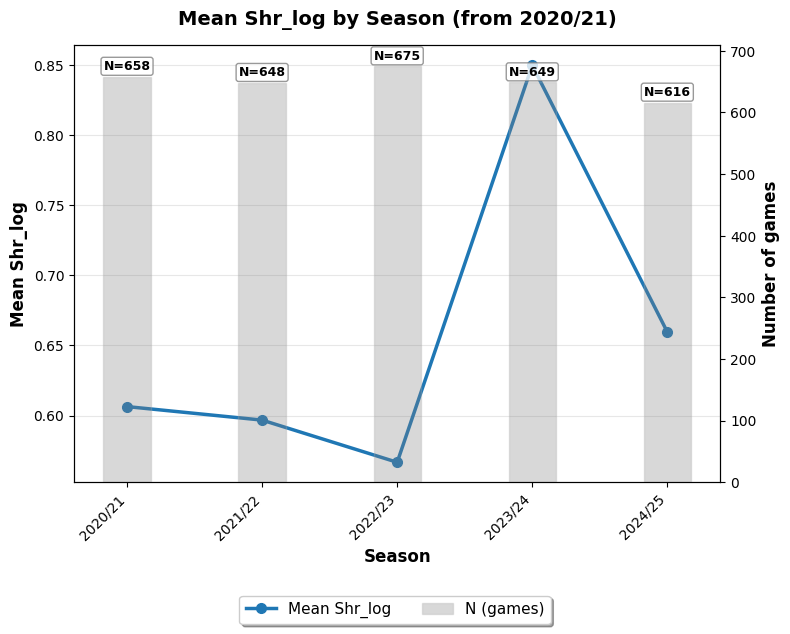

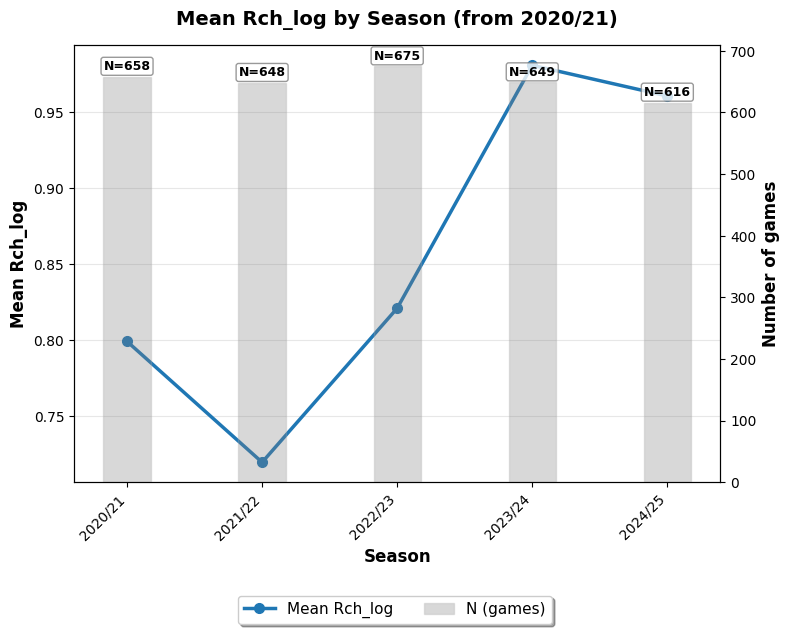


Seasonal summary (descriptive):
- Highest mean Rat_log: 2024/25 (mean=7.688, N=616)
  Lowest  mean Rat_log: 2021/22 (mean=5.595, N=648)
- Highest mean Shr_log: 2023/24 (mean=0.850, N=649)
  Lowest  mean Shr_log: 2022/23 (mean=0.567, N=675)
- Highest mean Rch_log: 2023/24 (mean=0.981, N=649)
  Lowest  mean Rch_log: 2021/22 (mean=0.719, N=648)


In [420]:
# Means by Season (from 2020/21) + Median/Q3/Zero_% and N; optional Median plots

assert 'df_processed' in globals(), "Load df_processed first."
assert 'Data_Hora' in df_processed.columns, "Column 'Data_Hora' is required."

# Build Season (football: season starts in July) and keep >= 2020/21
dS = df_processed.copy()
dt = pd.to_datetime(dS['Data_Hora'], errors='coerce')
start_year = np.where(dt.dt.month >= 7, dt.dt.year, dt.dt.year - 1)
dS['Season_start'] = start_year
dS['Season'] = dS['Season_start'].astype(int).astype(str) + '/' + (dS['Season_start']+1).astype(int).astype(str).str[-2:]
dS = dS[dS['Season_start'] >= 2020].copy()

if dS.empty:
    display(pd.DataFrame({'Note': ['No data from season 2020/21 onwards.']}))
else:
    metrics = ['Rat_log','Shr_log','Rch_log']

    # Descriptive table per Season: Mean, Median, Q3, Zero_%, N
    rows = []
    for var in metrics:
        g = dS.groupby(['Season','Season_start'])[var]
        tmp = pd.DataFrame({
            'Season': g.mean().index.get_level_values('Season'),
            'Season_start': g.mean().index.get_level_values('Season_start'),
            'Metric': var,
            'N': g.count().values,
            'Zero_%': g.apply(lambda s: (s==0).mean()*100).values,
            'Mean': g.mean().values,
            'Median': g.median().values,
            'Q3': g.quantile(0.75).values
        })
        rows.append(tmp)
    desc_season = (pd.concat(rows, ignore_index=True)
                     .sort_values(['Season_start','Metric'])
                     .drop(columns='Season_start')
                     .round(3))
    display(desc_season)

    # Line charts per metric with optional Median and N bars
    use_median = False   # <- mudar para True para traçar Median em vez de Mean
    for var in metrics:
        s_mean = (dS.groupby(['Season','Season_start'])[var].mean()
                    .reset_index().sort_values('Season_start'))
        s_med  = (dS.groupby(['Season','Season_start'])[var].median()
                    .reset_index().sort_values('Season_start'))
        s_n    = (dS.groupby(['Season','Season_start']).size()
                    .reset_index(name='N').sort_values('Season_start'))

        s = s_med if use_median else s_mean
        y_label = 'Median' if use_median else 'Mean'

        # Merge for aligned X
        s_plot = s.merge(s_n, on=['Season','Season_start'], how='left')
        x = np.arange(len(s_plot))

        # Increased figure size to accommodate bottom legend
        fig, ax1 = plt.subplots(figsize=(8,6.5))  # Reduced height but still enough space
        ax1.plot(x, s_plot[var], marker='o', label=f'{y_label} {var}', 
                linewidth=2.5, markersize=7, color='#1f77b4')
        ax1.set_title(f'{y_label} {var} by Season (from 2020/21)', 
                     fontsize=14, fontweight='bold', pad=15)
        ax1.set_xlabel('Season', fontsize=12, fontweight='bold')
        ax1.set_ylabel(f'{y_label} {var}', fontsize=12, fontweight='bold')
        ax1.set_xticks(x)
        ax1.set_xticklabels(s_plot['Season'], rotation=45, ha='right', fontsize=10)
        ax1.grid(True, axis='y', alpha=0.3)

        # Secondary axis: N (bars)
        ax2 = ax1.twinx()
        ax2.bar(x, s_plot['N'], width=0.35, alpha=0.3, label='N (games)', 
               color='gray', edgecolor='darkgray')
        ax2.set_ylabel('Number of games', fontsize=12, fontweight='bold')

        # Annotate N above the bars
        for xi, ni in zip(x, s_plot['N']):
            ax2.annotate(f'N={int(ni)}', (xi, ni), textcoords='offset points',
                         xytext=(0, 5), ha='center', fontsize=9, fontweight='bold',
                         bbox=dict(boxstyle='round,pad=0.2', facecolor='white', 
                                  alpha=0.8, edgecolor='gray'))

        # Adjust layout first to get proper spacing
        plt.tight_layout()
        plt.subplots_adjust(bottom=0.25)  # More space for legend
        
        # Combined legend positioned well below the x-axis labels
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        fig.legend(h1+h2, l1+l2, loc='lower center', bbox_to_anchor=(0.5, 0.02), 
                  ncol=2, frameon=True, fancybox=True, shadow=True, fontsize=11)

        plt.show()

    # Printed summary
    print("\nSeasonal summary (descriptive):")
    for var in metrics:
        # pick the table matching the chosen statistic for fairness
        tbl = desc_season[desc_season['Metric']==var].copy()
        # use Mean for summary textual (keeps consistency with your original block)
        tbl = tbl[['Season','Mean','N']].reset_index(drop=True)
        # top / bottom by Mean
        top = tbl.sort_values('Mean', ascending=False).iloc[0]
        bot = tbl.sort_values('Mean', ascending=True).iloc[0]
        print(f"- Highest mean {var}: {top['Season']} (mean={top['Mean']:.3f}, N={int(top['N'])})")
        print(f"  Lowest  mean {var}: {bot['Season']} (mean={bot['Mean']:.3f}, N={int(bot['N'])})")

* Há uma tendência crescente de 2020/21 → 2023/24 em todas as métricas (Rat, Shr, Rch), com máximos em 2023/24.

* Em 2024/25 observa-se uma ligeira redução face a 2023/24, mas os níveis mantêm-se acima de 2021/22 e 2022/23.

,Matchday,N,Mean Rat_log,Zero_% Rat_log,Pos_% Rat_log,Mean Shr_log,Zero_% Shr_log,Pos_% Shr_log,Mean Rch_log,Zero_% Rch_log,Pos_% Rch_log
0,1.0,245,5.577,32.653,67.347,0.591,31.429,68.571,0.703,33.878,66.122
1,2.0,245,5.778,29.796,70.204,0.575,33.061,66.939,0.718,33.469,66.531
2,3.0,245,5.793,30.612,69.388,0.538,35.102,64.898,0.773,28.980,71.020
3,4.0,245,5.753,30.204,69.796,0.567,30.612,69.388,0.769,32.653,67.347
4,5.0,245,5.738,31.837,68.163,0.563,30.612,69.388,0.773,25.714,74.286
5,6.0,245,5.365,34.694,65.306,0.542,32.245,67.755,0.660,39.592,60.408
6,7.0,245,5.190,35.918,64.082,0.507,33.878,66.122,0.712,33.878,66.122
7,8.0,245,5.720,31.429,68.571,0.569,31.429,68.571,0.698,30.612,69.388
8,9.0,245,5.594,31.429,68.571,0.499,32.653,67.347,0.753,31.837,68.163
9,10.0,245,5.367,34.286,65.714,0.559,34.694,65.306,0.717,28.571,71.429


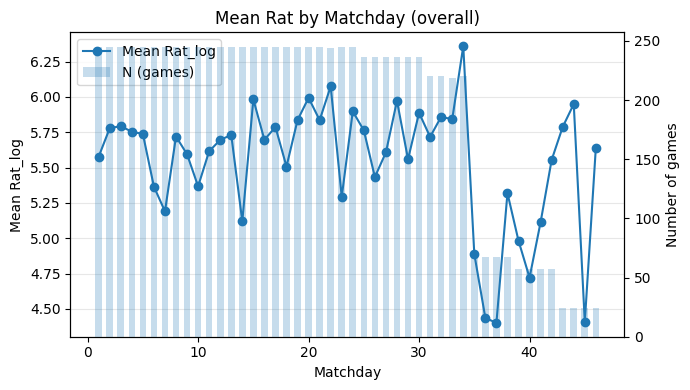

,Competition,Matchday,N,Mean Rat_log,Zero_% Rat_log,Pos_% Rat_log,Mean Shr_log,Zero_% Shr_log,Pos_% Shr_log,Mean Rch_log,Zero_% Rch_log,Pos_% Rch_log
0,Liga Portugal Betclic,1.0,115,5.809,30.435,69.565,0.546,35.652,64.348,0.638,40.000,60.000
1,Liga Portugal Betclic,2.0,115,5.526,32.174,67.826,0.543,32.174,67.826,0.676,33.913,66.087
2,Liga Portugal Betclic,3.0,115,5.464,34.783,65.217,0.543,33.913,66.087,0.729,30.435,69.565
3,Liga Portugal Betclic,4.0,115,6.104,25.217,74.783,0.627,31.304,68.696,0.784,31.304,68.696
4,Liga Portugal Betclic,5.0,115,5.189,38.261,61.739,0.583,33.043,66.957,0.760,28.696,71.304
...,...,...,...,...,...,...,...,...,...,...,...,...
75,Liga Portugal Meu Super,42.0,57,5.554,31.579,68.421,0.523,42.105,57.895,0.657,33.333,66.667
76,Liga Portugal Meu Super,43.0,24,5.787,29.167,70.833,0.389,37.500,62.500,0.692,33.333,66.667
77,Liga Portugal Meu Super,44.0,24,5.949,33.333,66.667,0.637,29.167,70.833,0.618,37.500,62.500
78,Liga Portugal Meu Super,45.0,24,4.407,45.833,54.167,0.595,37.500,62.500,0.985,20.833,79.167


,Competition,Max matchday
0,Liga Portugal Betclic,34.0
1,Liga Portugal Meu Super,46.0


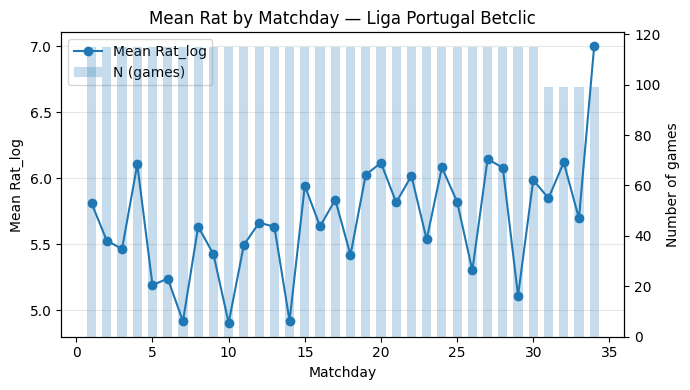

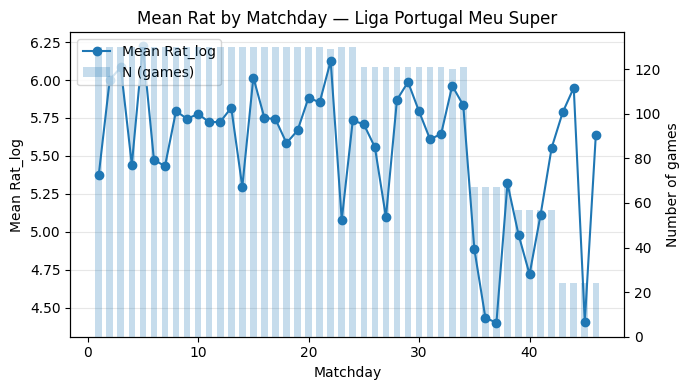

In [421]:
# Matchday (round) — overall and by competition: means, Zero_% and Pos_% (>0)

assert 'df_processed' in globals(), "Load df_processed first."

d = df_processed.copy()

# Detect matchday column (handles: 'Jornada', 'Matchday', 'Round', ...)
cand = [c for c in d.columns if c.lower() in ['jornada','jornada_num','matchday','round']]
if not cand:
    display(pd.DataFrame({'Note': ['No matchday column found to analyse rounds.']}))
else:
    d['Matchday'] = pd.to_numeric(d[cand[0]], errors='coerce')

    metrics = ['Rat_log','Shr_log','Rch_log']

    # ---------- OVERALL (univariate) ----------
    rows = []
    for md, g in d.groupby('Matchday'):
        rec = {'Matchday': md, 'N': len(g)}
        for m in metrics:
            rec[f'Mean {m}']  = g[m].mean()
            rec[f'Zero_% {m}'] = (g[m] == 0).mean() * 100
            rec[f'Pos_% {m}']  = (g[m] > 0).mean() * 100  # "com audiências"
        rows.append(rec)
    tab_md_overall = pd.DataFrame(rows).sort_values('Matchday')
    display(tab_md_overall.round(3))

    # Linha de Mean Rat por jornada com N (robustez)
    min_n = 5
    sub = tab_md_overall[tab_md_overall['N'] >= min_n]
    if not sub.empty:
        fig, ax1 = plt.subplots(figsize=(7,4))
        ax1.plot(sub['Matchday'], sub['Mean Rat_log'], marker='o', label='Mean Rat_log')
        ax1.set_title('Mean Rat by Matchday (overall)')
        ax1.set_xlabel('Matchday'); ax1.set_ylabel('Mean Rat_log')
        ax1.grid(True, axis='y', alpha=0.3)
        ax2 = ax1.twinx()
        ax2.bar(sub['Matchday'], sub['N'], width=0.6, alpha=0.25, label='N (games)')
        ax2.set_ylabel('Number of games')
        h1,l1 = ax1.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
        ax1.legend(h1+h2, l1+l2, loc='upper left')
        plt.tight_layout(); plt.show()

    # ---------- BY COMPETITION (handles different number of rounds) ----------
    if 'Competicao' in d.columns:
        d = d.rename(columns={'Competicao':'Competition'})
        rows = []
        for (comp, md), g in d.groupby(['Competition','Matchday']):
            rec = {'Competition': comp, 'Matchday': md, 'N': len(g)}
            for m in metrics:
                rec[f'Mean {m}']   = g[m].mean()
                rec[f'Zero_% {m}'] = (g[m] == 0).mean() * 100
                rec[f'Pos_% {m}']  = (g[m] > 0).mean() * 100
            rows.append(rec)
        tab_md_comp = pd.DataFrame(rows).sort_values(['Competition','Matchday'])
        display(tab_md_comp.round(3))

        # Máximo nº de jornadas por competição (confirma que a 1.ª tem menos jornadas)
        max_md = (tab_md_comp.groupby('Competition')['Matchday']
                  .max().reset_index().rename(columns={'Matchday':'Max matchday'}))
        display(max_md)

        # Gráficos por competição (Mean Rat + N)
        for comp, g in tab_md_comp.groupby('Competition'):
            sub = g[g['N'] >= min_n]
            if sub.empty:
                continue
            fig, ax1 = plt.subplots(figsize=(7,4))
            ax1.plot(sub['Matchday'], sub['Mean Rat_log'], marker='o', label='Mean Rat_log')
            ax1.set_title(f'Mean Rat by Matchday — {comp}')
            ax1.set_xlabel('Matchday'); ax1.set_ylabel('Mean Rat_log')
            ax1.grid(True, axis='y', alpha=0.3)
            ax2 = ax1.twinx()
            ax2.bar(sub['Matchday'], sub['N'], width=0.6, alpha=0.25, label='N (games)')
            ax2.set_ylabel('Number of games')
            h1,l1 = ax1.get_legend_handles_labels(); h2,l2 = ax2.get_legend_handles_labels()
            ax1.legend(h1+h2, l1+l2, loc='upper left')
            plt.tight_layout(); plt.show()
    else:
        display(pd.DataFrame({'Note':['Column "Competicao" not found; competition split skipped.']}))

In [422]:
# Highs and Lows — Top 10 highest and lowest positive per metric

show_cols = ['Data_Hora']
for c in ['Competicao','Season','EquipaCasa','EquipaFora']:
    if c in df_processed.columns: show_cols.append(c)

for m in ['Rat_log','Shr_log','Rch_log']:
    print(f'\nTop 10 highest {m}:')
    top = (df_processed[show_cols + [m]]
           .dropna(subset=[m])
           .sort_values(m, ascending=False)
           .head(10))
    display(top)

    print(f'Top 10 lowest positive {m}:')
    low_pos = (df_processed[df_processed[m] > 0][show_cols + [m]]
               .sort_values(m, ascending=True)
               .head(10))
    display(low_pos)


Top 10 highest Rat_log:


,Data_Hora,Competicao,EquipaCasa,EquipaFora,Rat_log
7470,2021-11-27 14:00:00+00:00,Liga Portugal Meu Super,Varzim SC,FC Penafiel,10.835278
6838,2021-01-03 17:00:00+00:00,Liga Portugal Meu Super,Leixões SC,SC Covilhã,10.835278
5385,2019-01-12 20:29:00+00:00,Liga Portugal Betclic,Boavista FC,Marítimo M,10.835278
2936,2016-01-10 16:00:00+00:00,Liga Portugal Betclic,A Académica,CD Tondela,10.835278
6590,2021-02-21 15:00:00+00:00,Liga Portugal Betclic,FC PFerreira,Vitória SC,10.835278
8756,2023-10-28 11:00:00+00:00,Liga Portugal Meu Super,SCU Torreense,FC PFerreira,10.835278
588,2012-08-19 18:00:00+00:00,Liga Portugal Meu Super,Sporting CP B,Vitória SC B,10.835278
5651,2018-12-16 17:00:00+00:00,Liga Portugal Meu Super,UD Oliveirense,CD C Piedade,10.835278
4252,2017-01-23 16:00:00+00:00,Liga Portugal Meu Super,Sporting CP B,SC Covilhã,10.835278
115,2009-11-11 16:00:00+00:00,Allianz Cup,Gil Vicente FC,Rio Ave FC,10.835278


Top 10 lowest positive Rat_log:


,Data_Hora,Competicao,EquipaCasa,EquipaFora,Rat_log
9554,2025-04-05 18:00:00+00:00,Liga Portugal Meu Super,GD Chaves,FC Vizela,6.242223
9553,2025-04-05 15:30:00+00:00,Liga Portugal Meu Super,Marítimo M,Leixões SC,6.242223
9572,2025-04-19 11:00:00+00:00,Liga Portugal Meu Super,FC Penafiel,CD Feirense,6.246107
9573,2025-04-19 14:00:00+00:00,Liga Portugal Meu Super,Académico,SCU Torreense,6.246107
5472,2019-03-30 18:00:00+00:00,Liga Portugal Betclic,GD Chaves,Sporting CP,6.278521
1551,2013-12-11 15:00:00+00:00,Liga Portugal Meu Super,CD Aves,CD Tondela,6.278521
1738,2014-04-06 11:15:00+00:00,Liga Portugal Meu Super,CD Feirense,Sporting CP B,6.278521
2927,2016-01-06 16:00:00+00:00,Liga Portugal Betclic,CD Tondela,FC PFerreira,6.278521
2614,2015-03-22 16:00:00+00:00,Liga Portugal Meu Super,Santa Clara,SC Braga B,6.278521
7196,2021-12-28 17:00:00+00:00,Liga Portugal Betclic,CD Tondela,Gil Vicente FC,6.278521



Top 10 highest Shr_log:


...

,Data_Hora,Competicao,EquipaCasa,EquipaFora,Shr_log
192,2011-01-29 19:15:00+00:00,Allianz Cup,FC Penafiel,Naval,0.19062
5614,2018-11-04 16:00:00+00:00,Liga Portugal Meu Super,CD Mafra,SC Farense,0.19062
8099,2022-09-17 14:00:00+00:00,Liga Portugal Meu Super,FC Penafiel,Moreirense FC,0.19062
7058,2021-12-15 21:00:00+00:00,Allianz Cup,FC Porto,Rio Ave FC,0.19062
7240,2022-02-01 20:15:00+00:00,Liga Portugal Betclic,Santa Clara,Boavista FC,0.19062
9299,2025-05-16 19:00:00+00:00,Liga Portugal Betclic,FC Famalicão,Casa Pia AC,0.19062
2221,2014-08-24 17:00:00+00:00,Liga Portugal Meu Super,CD Tondela,Atlético CP,0.19062
7036,2021-07-25 17:30:00+00:00,Allianz Cup,AFS,FC Arouca,0.19062
9474,2025-01-26 11:00:00+00:00,Liga Portugal Meu Super,FC Penafiel,FC Vizela,0.19062
9475,2025-01-26 14:00:00+00:00,Liga Portugal Meu Super,CD Mafra,UD Oliveirense,0.19062



Top 10 highest Rch_log:


,Data_Hora,Competicao,EquipaCasa,EquipaFora,Rch_log
114,2009-11-11 16:00:00+00:00,Allianz Cup,Fátima,Marítimo M,2.22029
4014,2016-08-13 16:00:00+00:00,Liga Portugal Meu Super,U Madeira,SC Braga B,2.22029
6589,2021-02-20 20:29:00+00:00,Liga Portugal Betclic,Sporting CP,Portimonense,2.22029
596,2012-08-22 21:00:00+00:00,Liga Portugal Meu Super,FC Penafiel,FC Arouca,2.22029
2689,2015-05-02 16:00:00+00:00,Liga Portugal Meu Super,SC Olhanense,GD Chaves,2.22029
8745,2023-10-02 20:15:00+00:00,Liga Portugal Meu Super,SCU Torreense,Belenenses,2.22029
6836,2021-01-03 11:15:00+00:00,Liga Portugal Meu Super,CD Mafra,GD Chaves,2.22029
5386,2019-01-13 15:00:00+00:00,Liga Portugal Betclic,CD Nacional,B SAD,2.22029
784,2012-12-30 18:59:00+00:00,Liga Portugal Meu Super,SL Benfica B,SC Freamunde,2.22029
5649,2018-12-15 18:00:00+00:00,Liga Portugal Meu Super,SC Farense,SC Braga B,2.22029


Top 10 lowest positive Rch_log:


,Data_Hora,Competicao,EquipaCasa,EquipaFora,Rch_log
9240,2025-03-30 15:30:00+00:00,Liga Portugal Betclic,Santa Clara,CD Nacional,0.41211
9246,2025-04-05 18:00:00+00:00,Liga Portugal Betclic,FC Arouca,FC Famalicão,0.41211
5825,2019-05-05 15:00:00+00:00,Liga Portugal Meu Super,SC Farense,Varzim SC,0.41211
9292,2025-05-10 18:00:00+00:00,Liga Portugal Betclic,SL Benfica,Sporting CP,0.41211
2372,2014-11-23 15:00:00+00:00,Liga Portugal Meu Super,Vitória SC B,GD Chaves,0.41211
2369,2014-11-16 15:00:00+00:00,Liga Portugal Meu Super,Atlético CP,SC Farense,0.41211
6344,2020-01-18 15:00:00+00:00,Liga Portugal Meu Super,UD Oliveirense,CD Feirense,0.41211
6138,2020-06-23 18:59:00+00:00,Liga Portugal Betclic,Vitória FC,Rio Ave FC,0.41211
2412,2014-12-14 15:00:00+00:00,Liga Portugal Meu Super,Atlético CP,Santa Clara,0.41211
6295,2019-11-30 17:15:00+00:00,Liga Portugal Meu Super,Varzim SC,FC Penafiel,0.41211


Picos de audiência (Rat/Shr/Rch) concentram-se em jogos entre “grandes” (Derby/Clássico) e em prime-time (≈20:30–20:45).

Valores mínimos positivos ocorrem sobretudo na Liga Portugal Meu Super, em horários diurnos (11:00/15:30) e com clubes de menor tração.

Consistência entre métricas: Rat, Shr e Rch contam a mesma história — conteúdo (rivalidade) e janela horária são os principais drivers.

One-liner: “Os máximos de audiência surgem em Derby/Clássico da Betclic em prime-time; os mínimos positivos, na Meu Super em horários diurnos — confirmando que rivalidade + horário nobre explicam os picos.”

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


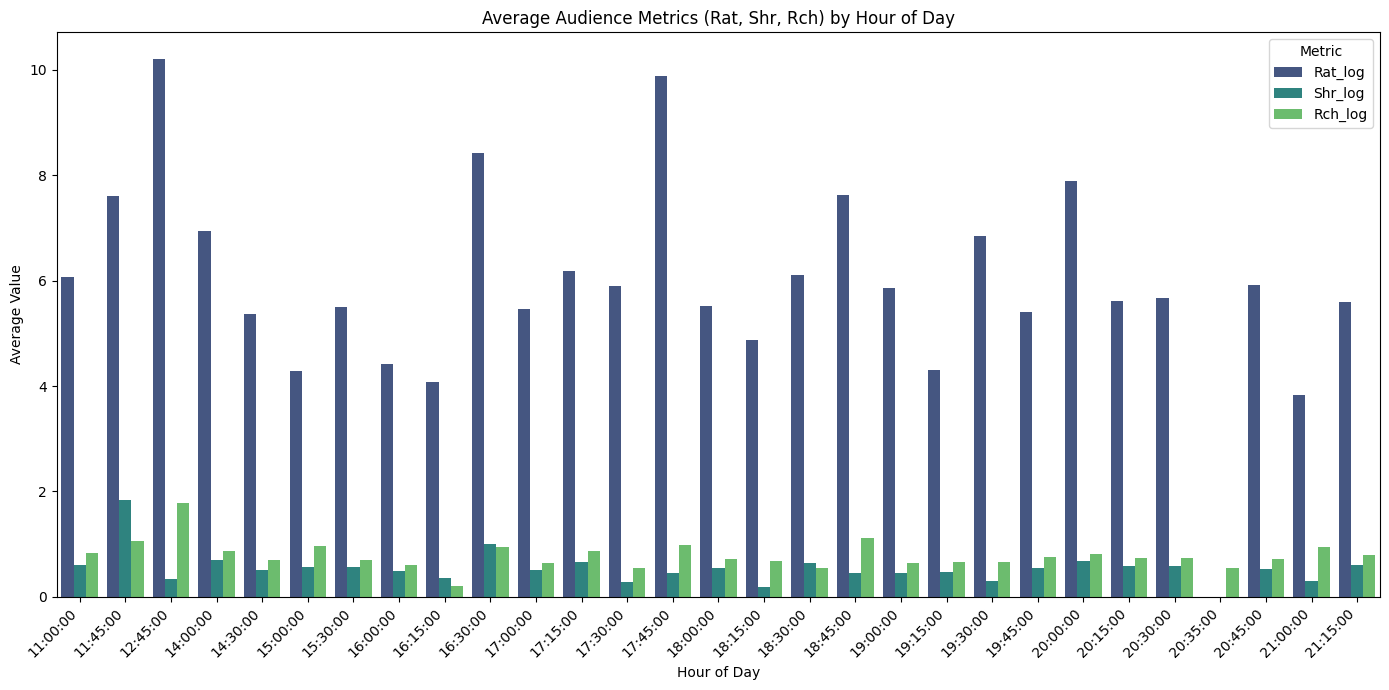

In [423]:
# --- Step 1: Clean 'final_slot' in the original DataFrame ---
df_processed['final_slot_clean'] = df_processed['final_slot'].str.extract(r'(\d{1,2}:\d{2}:\d{2})')[0]
df_processed['final_slot_clean'] = pd.to_datetime(df_processed['final_slot_clean'], format='%H:%M:%S').dt.time

# --- Step 2: Calculate mean by cleaned time ---
mean_audience_by_hour = df_processed.groupby('final_slot_clean')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()
mean_audience_by_hour = mean_audience_by_hour.sort_values('final_slot_clean')

# --- Step 3: Melt for plotting ---
mean_audience_melted_hour = mean_audience_by_hour.melt(
    id_vars='final_slot_clean',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# --- Step 4: Plot ---
plt.figure(figsize=(14, 7))
sns.barplot(x='final_slot_clean', y='Mean Value', hue='Metric', data=mean_audience_melted_hour, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


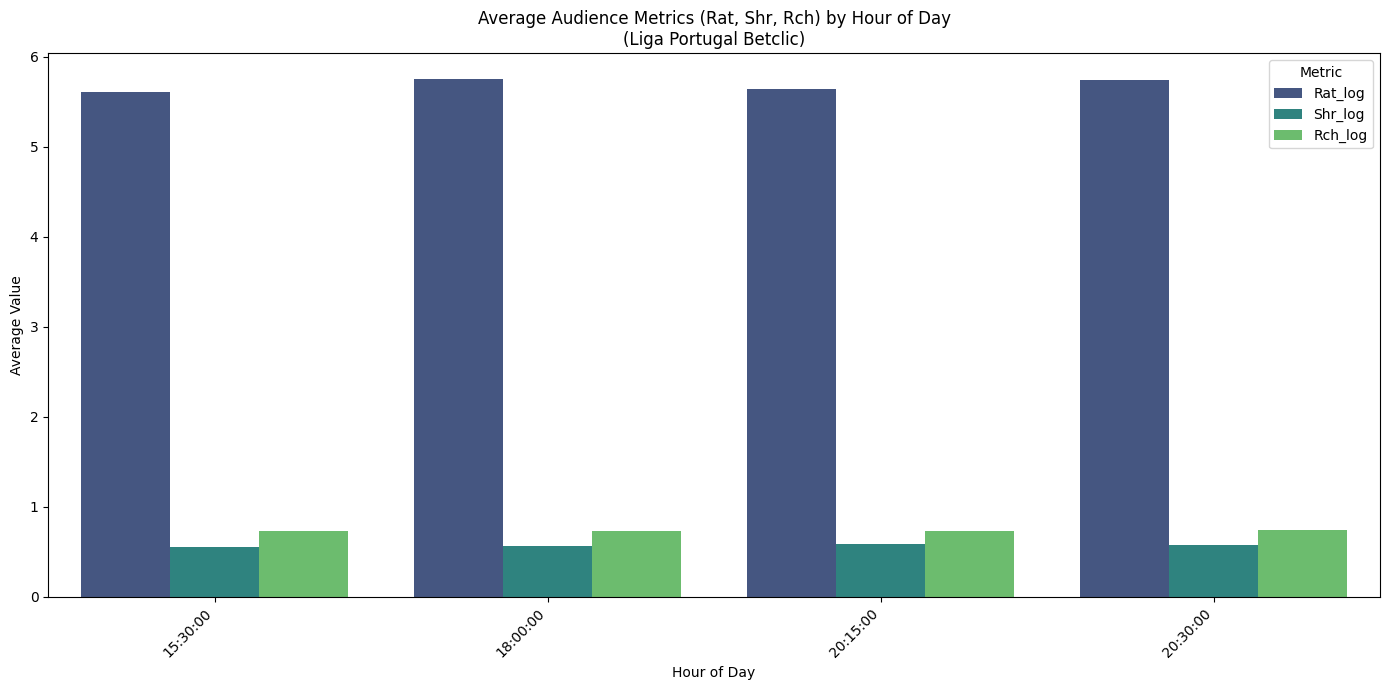

In [424]:
# Filter for Competicao = 'Liga Portugal Betclic'
df_filtered = df_processed[df_processed['Competicao'] == 'Liga Portugal Betclic']

# Calculate the mean of 'Rat_log', 'Shr_log', and 'Rch_log' by 'hora_corrigida'
mean_audience_by_hour = df_filtered.groupby('final_slot_clean')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()

# Sort by time
mean_audience_by_hour = mean_audience_by_hour.sort_values('final_slot_clean')

# Melt the DataFrame to long format for easier plotting with seaborn
mean_audience_melted_hour = mean_audience_by_hour.melt(
    id_vars='final_slot_clean',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 7))
sns.barplot(x='final_slot_clean', y='Mean Value', hue='Metric', data=mean_audience_melted_hour, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Hour of Day\n(Liga Portugal Betclic)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


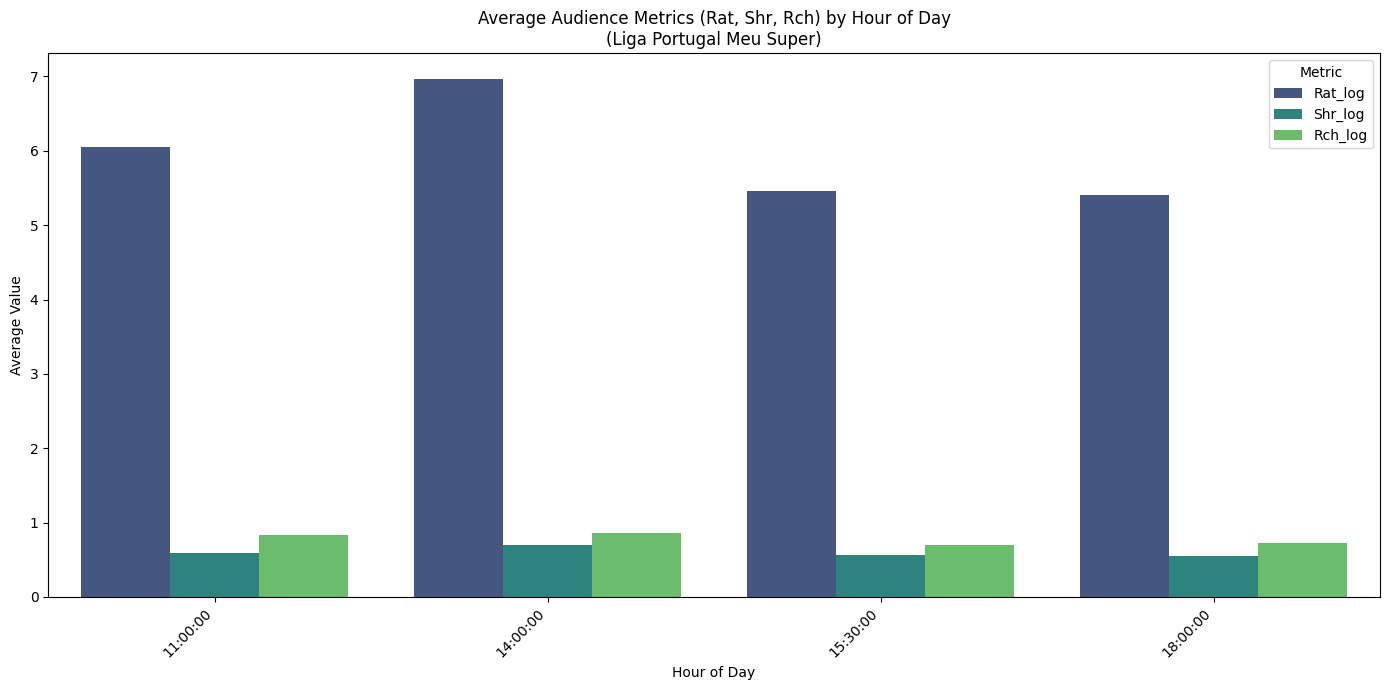

In [425]:
# Filter for Competicao = 'Liga Portugal Meu Super'
df_filtered = df_processed[df_processed['Competicao'] == 'Liga Portugal Meu Super']

# Calculate the mean of 'Rat_log', 'Shr_log', and 'Rch_log' by 'hora_corrigida'
mean_audience_by_hour = df_filtered.groupby('final_slot_clean')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()

# Sort by hora_corrigida
mean_audience_by_hour['final_slot_clean'] = pd.to_datetime(mean_audience_by_hour['final_slot_clean'], format='%H:%M:%S').dt.time
mean_audience_by_hour = mean_audience_by_hour.sort_values('final_slot_clean')

# Melt the DataFrame to long format for easier plotting with seaborn
mean_audience_melted_hour = mean_audience_by_hour.melt(
    id_vars='final_slot_clean',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 7))
sns.barplot(x='final_slot_clean', y='Mean Value', hue='Metric', data=mean_audience_melted_hour, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Hour of Day\n(Liga Portugal Meu Super)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


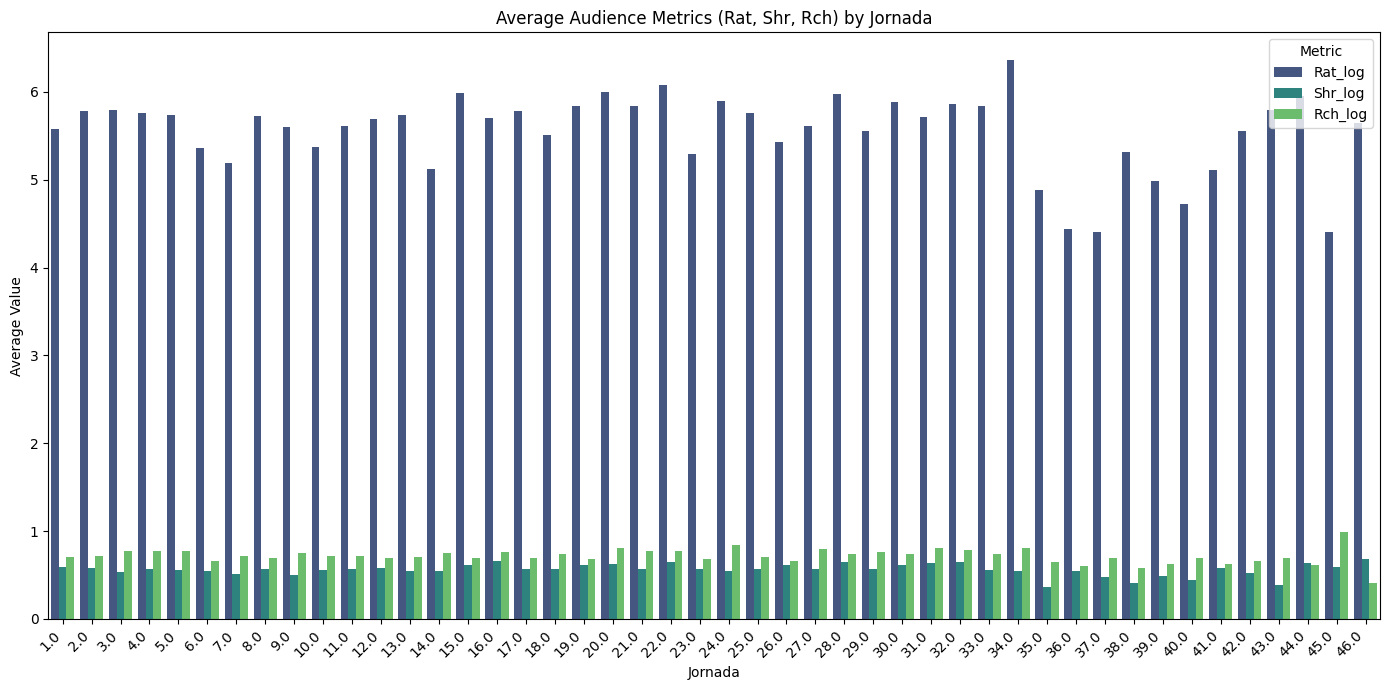

In [426]:
# Calculate the mean of 'Rat_log', 'Shr_log', and 'Rch_log' by 'Jornada'
mean_audience_by_jornada = df_processed.groupby('Jornada')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()

# Melt the DataFrame to long format for easier plotting with seaborn
mean_audience_melted_jornada = mean_audience_by_jornada.melt(
    id_vars='Jornada',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 7))
sns.barplot(x='Jornada', y='Mean Value', hue='Metric', data=mean_audience_melted_jornada, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Jornada')
plt.xlabel('Jornada')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


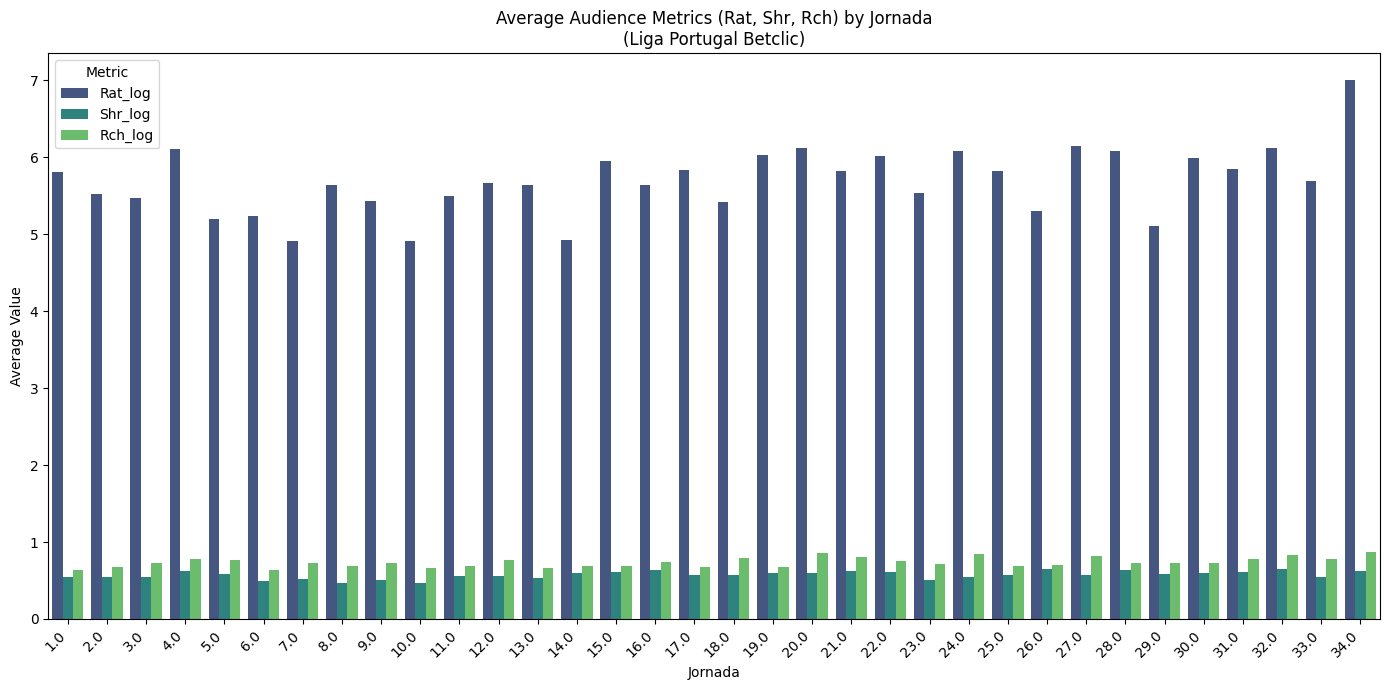

In [427]:
# Filter for Competicao = 'Liga Portugal Betclic'
df_filtered = df_processed[df_processed['Competicao'] == 'Liga Portugal Betclic']

# Calculate the mean of 'Rat_log', 'Shr_log', and 'Rch_log' by 'Jornada'
mean_audience_by_jornada = df_filtered.groupby('Jornada')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()

# Melt the DataFrame to long format for easier plotting with seaborn
mean_audience_melted_jornada = mean_audience_by_jornada.melt(
    id_vars='Jornada',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 7))
sns.barplot(x='Jornada', y='Mean Value', hue='Metric', data=mean_audience_melted_jornada, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Jornada\n(Liga Portugal Betclic)')
plt.xlabel('Jornada')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


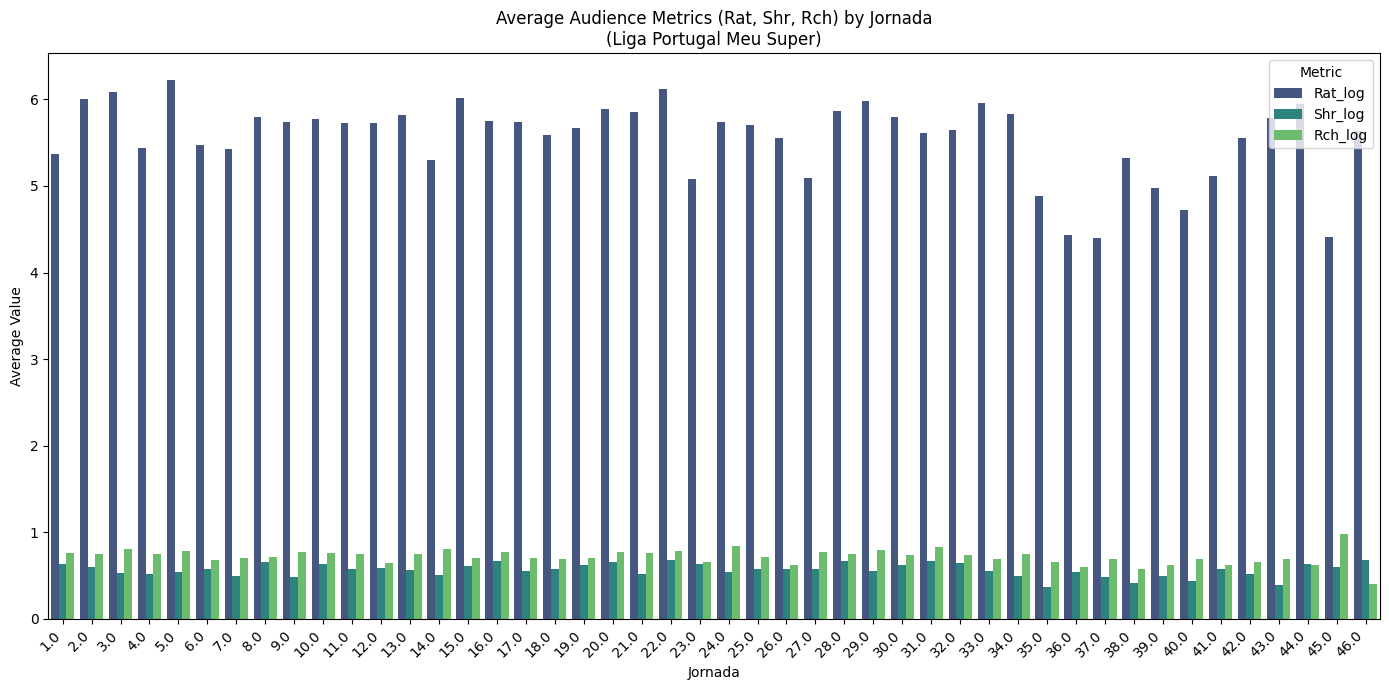

In [428]:
# Filter for Competicao = 'Liga Portugal Meu Super'
df_filtered = df_processed[df_processed['Competicao'] == 'Liga Portugal Meu Super']

# Calculate the mean of 'Rat_log', 'Shr_log', and 'Rch_log' by 'Jornada'
mean_audience_by_jornada = df_filtered.groupby('Jornada')[['Rat_log', 'Shr_log', 'Rch_log']].mean().reset_index()

# Melt the DataFrame to long format for easier plotting with seaborn
mean_audience_melted_jornada = mean_audience_by_jornada.melt(
    id_vars='Jornada',
    value_vars=['Rat_log', 'Shr_log', 'Rch_log'],
    var_name='Metric',
    value_name='Mean Value'
)

# Create the grouped bar chart
plt.figure(figsize=(14, 7))
sns.barplot(x='Jornada', y='Mean Value', hue='Metric', data=mean_audience_melted_jornada, palette='viridis')
plt.title('Average Audience Metrics (Rat, Shr, Rch) by Jornada\n(Liga Portugal Meu Super)')
plt.xlabel('Jornada')
plt.ylabel('Average Value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

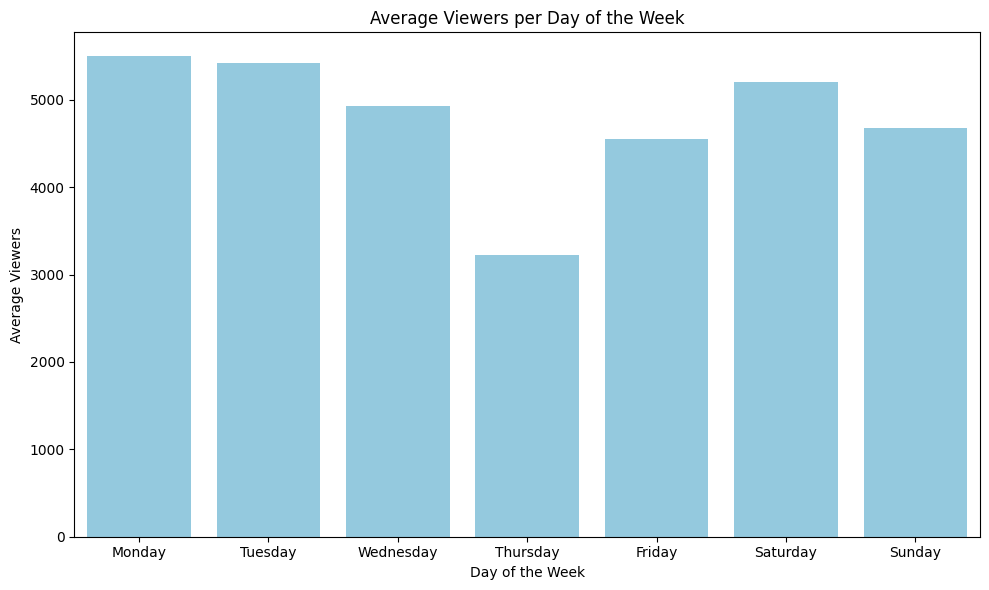

In [429]:
# Calcular média de espectadores por dia da semana já com nome
mean_viewers_corrigido = (
    df_processed
    .groupby(['Weekday_num', 'Weekday_name'])['Espetadores']
    .mean()
    .reset_index()
)

# Definir ordem correta dos dias da semana
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Converter 'Weekday_name' para categórico ordenado
mean_viewers_corrigido['Weekday_name'] = pd.Categorical(
    mean_viewers_corrigido['Weekday_name'],
    categories=weekday_order,
    ordered=True
)

# Ordenar corretamente
mean_viewers_corrigido = mean_viewers_corrigido.sort_values('Weekday_name')

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Weekday_name', y='Espetadores', data=mean_viewers_corrigido, color='skyblue')
plt.title('Average Viewers per Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Viewers')
plt.tight_layout()
plt.show()

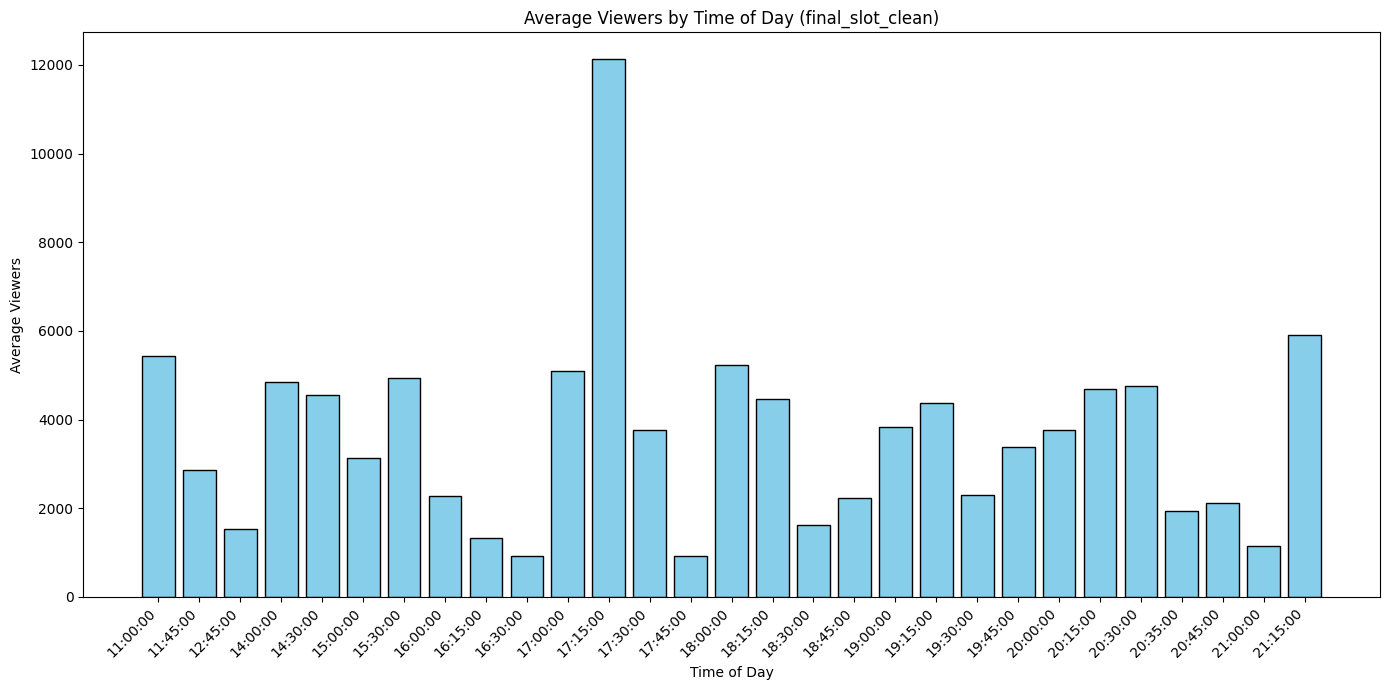

In [430]:
# Ensure 'final_slot' is in time format
df_processed['final_slot_clean'] = pd.to_datetime(df_processed['final_slot_clean'], format='%H:%M:%S', errors='coerce').dt.time

# Calculate mean viewers per 'final_slot'
mean_viewers_by_final_slot = df_processed.groupby('final_slot_clean')['Espetadores'].mean().reset_index()

# Sort by time for plotting
mean_viewers_by_final_slot = mean_viewers_by_final_slot.sort_values('final_slot_clean')

# Plotting
plt.figure(figsize=(14, 7))
plt.bar(mean_viewers_by_final_slot['final_slot_clean'].astype(str),
        mean_viewers_by_final_slot['Espetadores'],
        color='skyblue', edgecolor='black')
plt.title('Average Viewers by Time of Day (final_slot_clean)')
plt.xlabel('Time of Day')
plt.ylabel('Average Viewers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

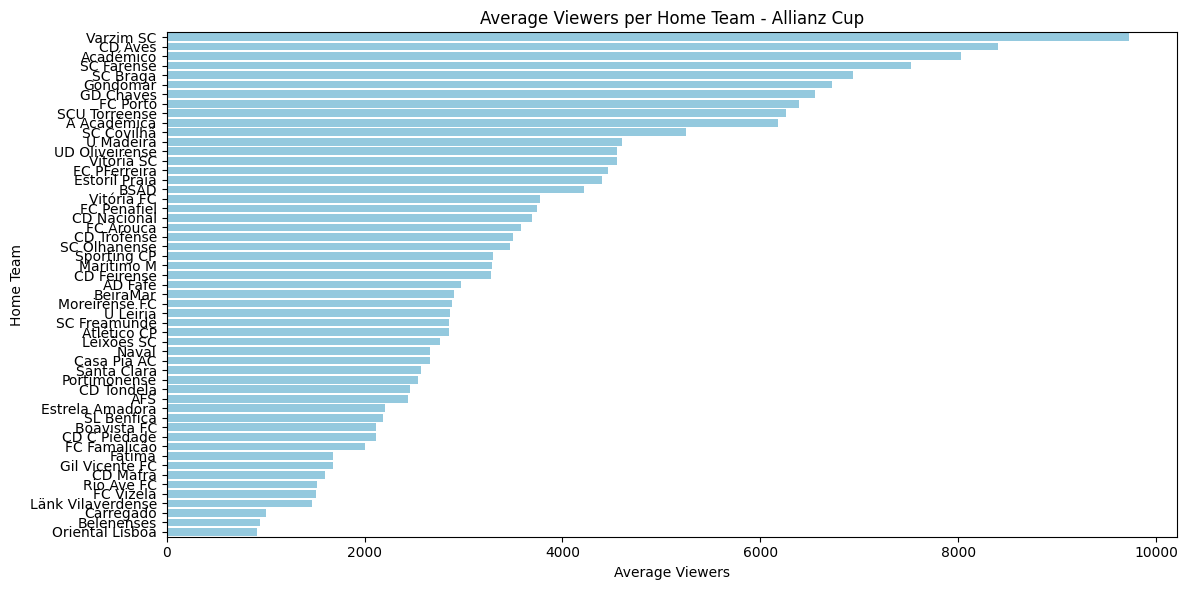

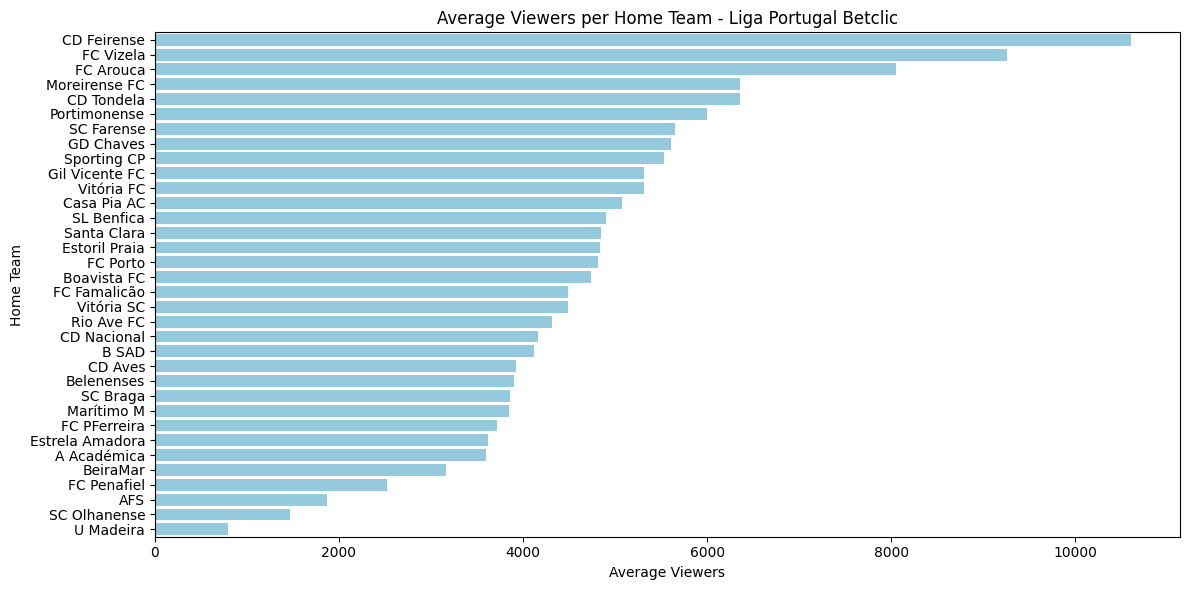

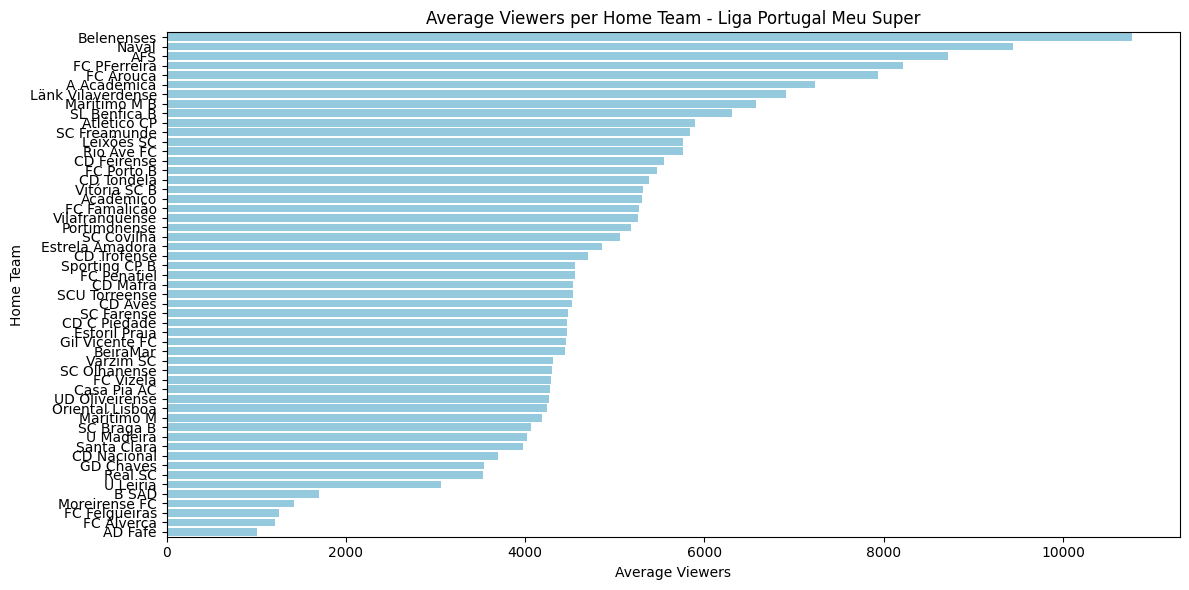

In [431]:
# Calcular a média de espectadores por equipa da casa e competição
media_espectadores_casa_comp = (
    df_processed
    .groupby(['Competicao', 'EquipaCasa'])['Espetadores']
    .mean()
    .reset_index()
)

# Ordenar por competição e média de espectadores (decrescente)
media_espectadores_casa_comp = media_espectadores_casa_comp.sort_values(['Competicao', 'Espetadores'], ascending=[True, False])

# Visualizar em gráfico de barras, um gráfico por competição
for competicao in media_espectadores_casa_comp['Competicao'].unique():
    dados = media_espectadores_casa_comp[media_espectadores_casa_comp['Competicao'] == competicao]
    plt.figure(figsize=(12, 6))
    sns.barplot(x='Espetadores', y='EquipaCasa', data=dados, color='skyblue')
    plt.title(f'Average Viewers per Home Team - {competicao}')
    plt.xlabel('Average Viewers')
    plt.ylabel('Home Team')
    plt.tight_layout()
    plt.show()

In [432]:
# Count the number of games for each competition
game_counts_by_competition = df_processed['Competicao'].value_counts()

print("Number of games per competition:")
display(game_counts_by_competition)

Number of games per competition:


Competicao
Liga Portugal Meu Super    4920
Liga Portugal Betclic      3846
Allianz Cup                 848
Name: count, dtype: int64

**HEATMAPS**

Heatmaps divididos inicialmente por campeonatos. A variável CampeaoAnterior aparece a vazio porque o campeão sobe para a liga Betclic

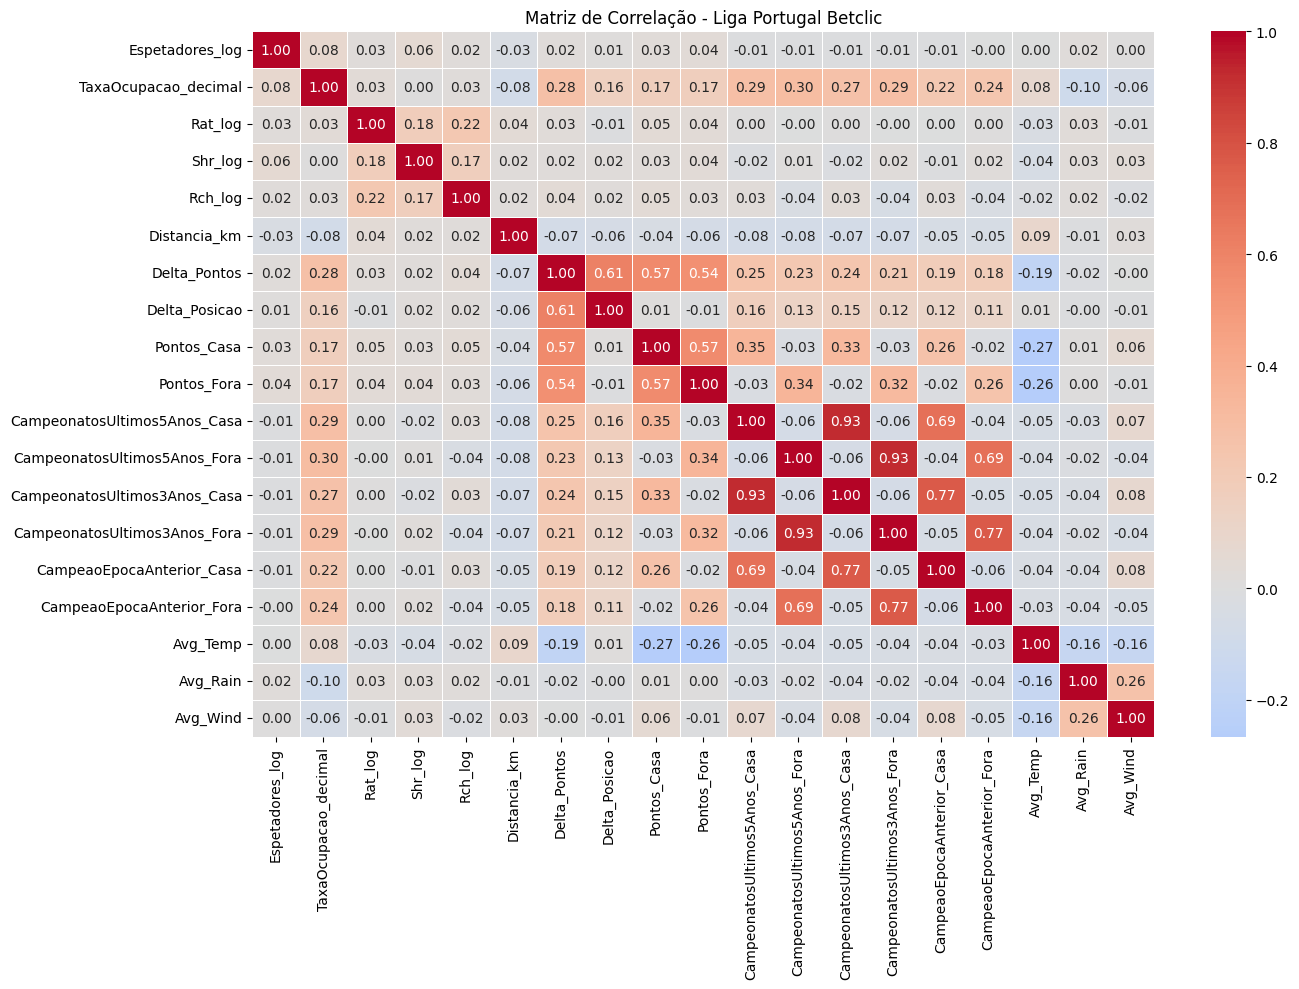

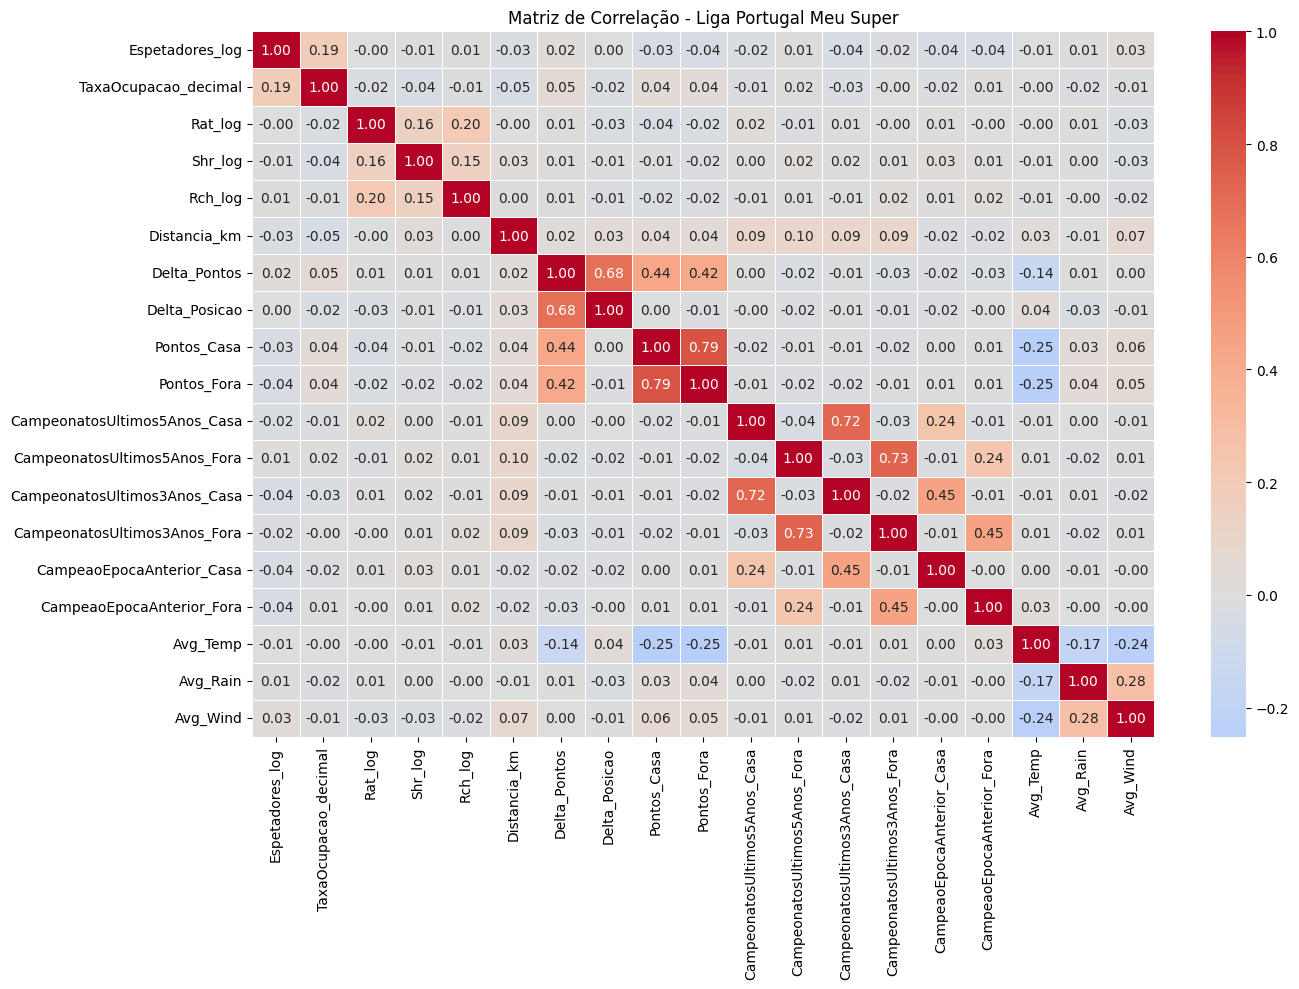

In [433]:

# Variáveis que vamos analisar
features_corr = [
    'Espetadores_log',
    'TaxaOcupacao_decimal',
    'Rat_log',
    'Shr_log',
    'Rch_log',
    'Distancia_km',
    'Delta_Pontos',
    'Delta_Posicao',
    'Pontos_Casa',
    'Pontos_Fora',
    'CampeonatosUltimos5Anos_Casa',
    'CampeonatosUltimos5Anos_Fora',
    'CampeonatosUltimos3Anos_Casa',
    'CampeonatosUltimos3Anos_Fora',
    'CampeaoEpocaAnterior_Casa',
    'CampeaoEpocaAnterior_Fora',
    'Avg_Temp',
    'Avg_Rain',
    'Avg_Wind'
]

# Garantir que só usamos colunas que existem
features_corr = [col for col in features_corr if col in df_processed.columns]

# Função para desenhar heatmap para uma liga específica
def plot_corr_heatmap(df, liga, features):
    subset = df[df['Competicao'] == liga][features].dropna()
    corr = subset.corr()
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True, linewidths=0.5)
    plt.title(f"Matriz de Correlação - {liga}")
    plt.tight_layout()
    plt.show()

# Heatmap para cada liga
plot_corr_heatmap(df_processed, "Liga Portugal Betclic", features_corr)
plot_corr_heatmap(df_processed, "Liga Portugal Meu Super", features_corr)

**HEATMAP - Sem o impacto dos 3 grandes (retirada de variáveis CampeonatosUltimos3Anos e CampeonatosUltimos5Anos)** - Mariana

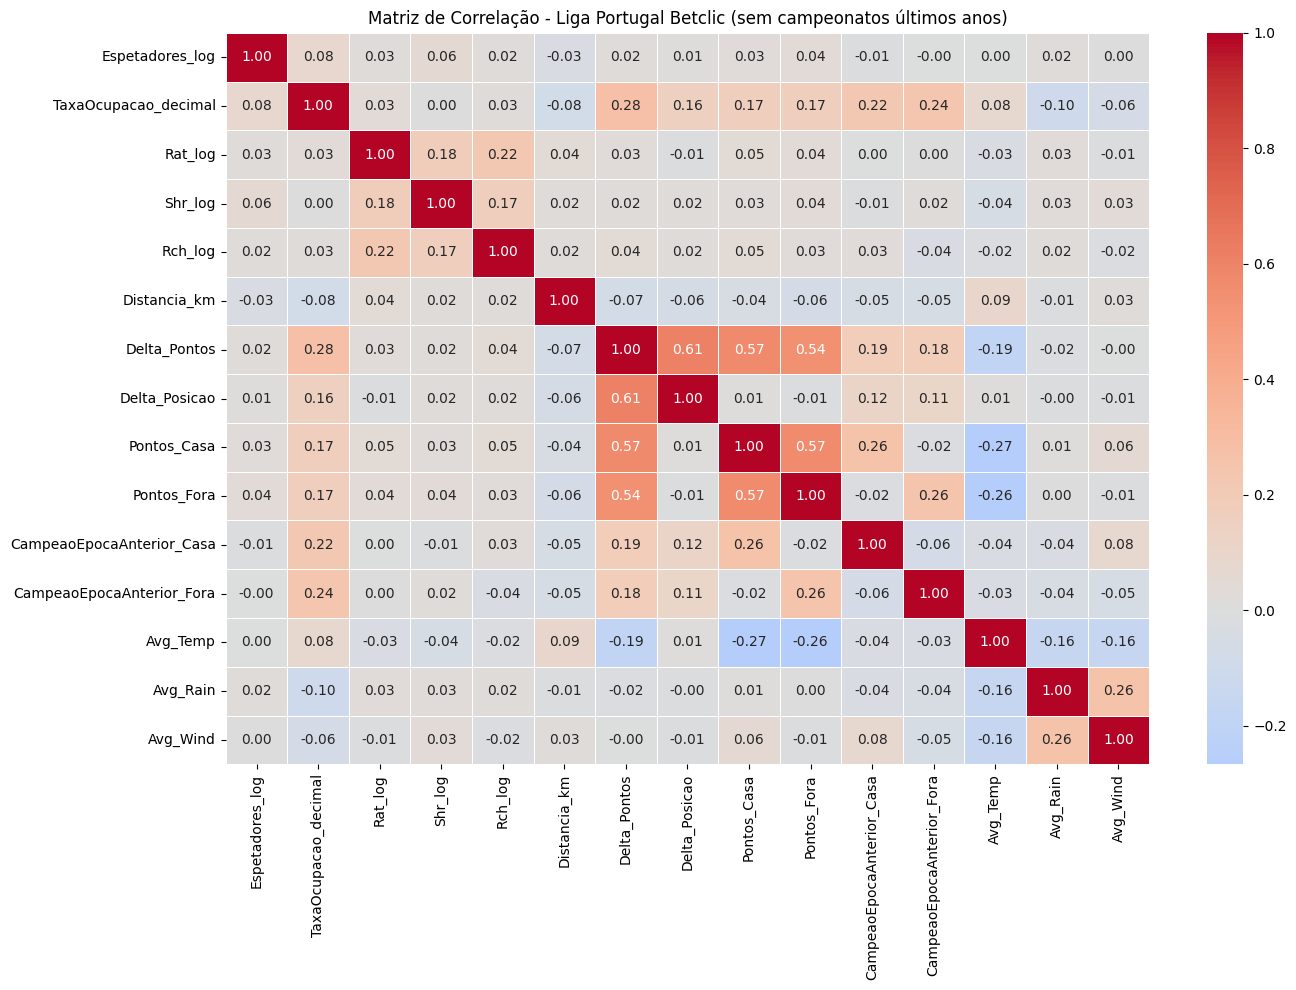

In [434]:
# Variáveis selecionadas para Betclic (sem campeonatos últimos anos)
features_corr_betclic_reduced = [
    # Audiência e estádio
    'Espetadores_log',
    'TaxaOcupacao_decimal',
    'Rat_log',
    'Shr_log',
    'Rch_log',
    'Distancia_km',
    
    # Competitividade (classificação/jogo)
    'Delta_Pontos',
    'Delta_Posicao',
    'Pontos_Casa',
    'Pontos_Fora',
    
    # Campeão da época anterior
    'CampeaoEpocaAnterior_Casa',
    'CampeaoEpocaAnterior_Fora',
    
    # Condições externas (clima)
    'Avg_Temp',
    'Avg_Rain',
    'Avg_Wind'
]

# Garantir que só usamos colunas que existem no df
features_corr_betclic_reduced = [
    col for col in features_corr_betclic_reduced if col in df_processed.columns
]

# Filtrar só jogos da Liga Portugal Betclic
subset = df_processed[df_processed['Competicao'] == "Liga Portugal Betclic"][features_corr_betclic_reduced].dropna()

# Calcular correlação
corr = subset.corr()

# Plotar heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar=True, linewidths=0.5)
plt.title("Matriz de Correlação - Liga Portugal Betclic (sem campeonatos últimos anos)")
plt.tight_layout()
plt.show()